# User Behavior Anomaly Detection for Cybersecurity - 3

Supervised Learning for Login Behavior Analysis - SSO Login Risk and Account Takeover

**Author:** MiyukiMol  
**Target roles:** Data Scientist · Security Analyst · Threat Detection · Machine Learning Engineer  
**Tools:** Python, pandas, NumPy, LightGBM, CatBoost, scikit-learn, Matplotlib, Seaborn, Google Colab  
**Dataset:** [Login Data Set for Risk-Based Authentication (RBA)](https://www.kaggle.com/datasets/dasgroup/rba-dataset)

---

## 1 - Project Overview

### 1.1 Business Context
While unsupervised anomaly detection (such as Isolation Forest) establishes a baseline, real-world Security Operations Centers (SOC) require models that directly leverage confirmed attack labels (Account Takeover) while accounting for severe financial asymmetries. Traditional technical metrics like standard accuracy or F1-score optimization fail to reflect business reality, where missing a catastrophic attack results in massive regulatory fines (GDPR) and forensic incident costs, whereas false positives incur manageable manual review expenses.

### 1.2 Project Objective
The objective of this notebook is to transition from unsupervised anomaly detection to a supervised machine learning framework. We evaluate LightGBM as a baseline supervised model and leverage CatBoost to effectively handle categorical security features without arbitrary target encoding. Through chronological splitting and euro-based cost optimization, we show how model selection and threshold tuning ($T = 0.6748$) progressively minimize overall financial risk.

### 1.3 Research Questions
1. How does supervised CatBoost modeling improve threat detection compared to unsupervised baselines?
2. Why is chronological splitting critical to prevent temporal data leakage in production security systems?
3. How can euro-based business costs ($C_{FN}$ vs $C_{FP}$) be formulated to find the optimal classification threshold?
4. What is the business trade-off between incurring false positive review costs versus preventing catastrophic GDPR-related incident damages?

### 1.4 Notebook Structure
This notebook follows a production-grade supervised machine learning and cost-optimization workflow:
1. **Project Overview** — Objectives, business context, and structural design
2. **Environment Setup** — Importing libraries and configuring the environment
3. **Dataset Acquisition and Loading** — Loading and inspecting the full RBA dataset
4. **Data Preparation and Feature Engineering** — Processing security logs, handling categorical variables, and defining target features
5. **Chronological Splitting** — Splitting data chronologically to simulate a real-world production deployment and prevent future-unseen data leakage
6. **Supervised Model Training (LightGBM & CatBoost Comparison)** — Training gradient-boosted trees on historical data to classify account takeovers
7. **Business-Driven Cost Optimization** — Modeling euro-based asymmetric costs ($C_{FN}$ = 30,000 EUR, $C_{FP}$ = 30 EUR) to compute the optimal threshold ($T = 0.6748$)
8. **Model Evaluation & Confusion Matrix** — Analyzing final classification performance, Recall (98%), and total financial impact
9. **Key Findings and Next Steps** — Summarizing insights, the value of security "insurance premiums," and production deployment takeaways

### 1.5 Important Considerations
* The `Is Account Takeover` column serves as the target variable for supervised training and post-training evaluation.
* Chronological splitting ensures that future attack patterns never leak into the training set, reflecting a realistic production deployment.
* Threshold tuning is driven entirely by minimizing total financial risk (euro-based loss function) rather than maximizing traditional classification metrics.

## 2 - Environment Setup

### 2.1 Import Libraries

In [1]:
# 2.1 Import Libraries

# Data manipulation
import pandas as pd
import numpy as np
import os
import zipfile
from getpass import getpass

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning and preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


# Model evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve,
    roc_auc_score
)

# Utilities
import warnings
import random

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully.")
print("Random state:", RANDOM_STATE)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully.
Random state: 42
Pandas version: 2.2.3
NumPy version: 2.4.6


### 2.2 Environment Configuration

A fixed random state is used to improve reproducibility across experiments.

The visualization settings are configured to make charts easier to interpret.

The following configuration will be used throughout this notebook:

- **Random state:** 42
- **Visualization style:** Seaborn whitegrid
- **Machine learning library:** Scikit-learn, LightGBM, CatBoost

## 3 - Dataset Acquisition and Loading

This project uses the Login Data Set for Risk-Based Authentication (RBA) from Kaggle.

The dataset contains approximately 31.27 million login events, including login timestamps, user identifiers, login outcomes, device information, geographical information, and account-takeover labels.

A major challenge is the extreme class imbalance: only 141 events are labelled as account takeovers.

Therefore, this notebook uses a memory-efficient data-loading strategy to preserve rare positive cases while preparing data for supervised threat classification.

**Dataset source:** [Login Data Set for Risk-Based Authentication (RBA)](https://www.kaggle.com/datasets/dasgroup/rba-dataset)

### 3.1 Install Kaggle CLI

we will download the "**Login Data Set for Risk-Based Authentication**" dataset from Kaggle and load a manageable sample without extracting the entire large CSV to disk.

https://www.kaggle.com/datasets/dasgroup/rba-dataset

In [2]:
# Install the Kaggle CLI in the current Colab runtime.
%pip -q install kaggle

### 3.2 Configure Kaggle API Credentials

In [3]:
# Enter the Kaggle API token without displaying it.
# For a public portfolio, consider using Google Colab Secrets instead.
kaggle_token = getpass("Paste your Kaggle API token: ")
os.environ["KAGGLE_API_TOKEN"] = kaggle_token

Paste your Kaggle API token: ··········


### 3.3 Download the Dataset

In [4]:
# Download the dataset ZIP.
!kaggle datasets download -d dasgroup/rba-dataset -p /content

Dataset URL: https://www.kaggle.com/datasets/dasgroup/rba-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 1.10G/1.10G [00:11<00:00, 103MB/s]



### 3.4 Verify the Downloaded ZIP Archive

In [5]:
ZIP_PATH = "/content/rba-dataset.zip"

# Check whether the ZIP file exists
if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        "Dataset ZIP file was not found. Please check the download step."
    )

# Verify that the file is a valid ZIP archive
if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError("The downloaded file is not a valid ZIP archive.")

file_size_gb = os.path.getsize(ZIP_PATH) / (1024 ** 3)

print("ZIP archive verified successfully.")
print(f"File path: {ZIP_PATH}")
print(f"File size: {file_size_gb:.2f} GB")

ZIP archive verified successfully.
File path: /content/rba-dataset.zip
File size: 1.10 GB


### 3.5 Identify the CSV File

In [6]:
with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    csv_files = [
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
    ]

    if not csv_files:
        raise FileNotFoundError(
            "No CSV file was found in the ZIP archive."
        )

    print("CSV file(s) found:")

    for csv_file in csv_files:
        print(f"- {csv_file}")

if len(csv_files) > 1:
    raise ValueError(
        "Multiple CSV files found. Please identify the correct dataset."
    )

CSV_NAME = csv_files[0]

print(f"\nSelected CSV file: {CSV_NAME}")

CSV file(s) found:
- rba-dataset.csv

Selected CSV file: rba-dataset.csv


### 3.6 Inspect the Dataset Structure

In [7]:
with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    with archive.open(CSV_NAME) as file:
        df_preview = pd.read_csv(file, nrows=5)

print(f"Preview shape: {df_preview.shape}")

print("\nColumn names:")
print(df_preview.columns.tolist())

print("\nData types:")
print(df_preview.dtypes)

display(df_preview)

Preview shape: (5, 16)

Column names:
['index', 'Login Timestamp', 'User ID', 'Round-Trip Time [ms]', 'IP Address', 'Country', 'Region', 'City', 'ASN', 'User Agent String', 'Browser Name and Version', 'OS Name and Version', 'Device Type', 'Login Successful', 'Is Attack IP', 'Is Account Takeover']

Data types:
index                         int64
Login Timestamp              object
User ID                       int64
Round-Trip Time [ms]        float64
IP Address                   object
Country                      object
Region                       object
City                         object
ASN                           int64
User Agent String            object
Browser Name and Version     object
OS Name and Version          object
Device Type                  object
Login Successful               bool
Is Attack IP                   bool
Is Account Takeover            bool
dtype: object


,index,Login Timestamp,User ID,Round-Trip Time [ms],IP Address,Country,Region,City,ASN,User Agent String,Browser Name and Version,OS Name and Version,Device Type,Login Successful,Is Attack IP,Is Account Takeover
0,0,2020-02-03 12:43:30.772,-4324475583306591935,NaN,10.0.65.171,NO,-,-,29695,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...,Firefox 20.0.0.1618,iOS 13.4,mobile,False,False,False
1,1,2020-02-03 12:43:43.549,-4324475583306591935,NaN,194.87.207.6,AU,-,-,60117,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus...,Chrome Mobile 46.0.2490,Android 4.1,mobile,False,False,False
2,2,2020-02-03 12:43:55.873,-3284137479262433373,NaN,81.167.144.58,NO,Vestland,Urangsvag,29695,Mozilla/5.0 (iPad; CPU OS 7_1 like Mac OS X) ...,Android 2.3.3.2672,iOS 7.1,mobile,True,False,False
3,3,2020-02-03 12:43:56.180,-4324475583306591935,NaN,170.39.78.152,US,-,-,393398,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus...,Chrome Mobile WebView 85.0.4183,Android 4.1,mobile,False,False,False
4,4,2020-02-03 12:43:59.396,-4618854071942621186,NaN,10.0.0.47,US,Virginia,Ashburn,398986,Mozilla/5.0 (Linux; U; Android 2.2) Build/NMA...,Chrome Mobile WebView 85.0.4183,Android 2.2,mobile,False,True,False


### 3.7 Summary

The dataset has been successfully downloaded, verified, and inspected.

The initial preview contains 5 rows and 16 columns, including user identifiers, login timestamps, IP addresses, geographic information, device details, login outcomes, and security-related labels.

The dataset contains both numerical and categorical features, as well as Boolean variables.

The following observations were identified:

- `Login Timestamp` is initially stored as an object and will need datetime conversion.
- `User ID` is stored as an integer and can be used to identify user-related login patterns.
- `Login Successful`, `Is Attack IP`, and `Is Account Takeover` are Boolean variables.
- `Is Account Takeover` will be used as the evaluation target, not as an input feature during model training.
- `Is Attack IP` requires careful consideration to avoid potential data leakage.
- Some geographic fields contain placeholder values such as `-`, which will require further inspection during data preparation.

Since the dataset is large, we will use chunk-based processing in the next section to reduce memory consumption.

In the next section, we will prepare the dataset for supervised threat classification.



---



## 4 - Data Preparation

In this section, we prepare the dataset for supervised threat classification by performing memory-efficient chunk-based sampling and retaining all positive Account Takeover (ATO) events.

Since the original dataset contains millions of login events, we use chunk-based processing to reduce memory consumption.

We retain all Account Takeover (ATO) events and randomly sample a subset of non-ATO events for analysis.

The target label is kept separate from the input features to prevent data leakage.

### 4.1 Define Target and Feature Columns

We identify the target variable and select the initial features required for anomaly detection.

The `Is Account Takeover` column is reserved for model evaluation and will not be used during model training.

We initially select login-related and user-related information. Additional features will be engineered in a later section.

In [8]:
TARGET_COLUMN = "Is Account Takeover"

FEATURE_COLUMNS = [
    "User ID",
    "Login Timestamp",
    "Login Successful",
    "Country",
    "Device Type",
    "IP Address"
]

USE_COLUMNS = FEATURE_COLUMNS + [TARGET_COLUMN]

print("Target column:", TARGET_COLUMN)
print("\nSelected feature columns:")
print(FEATURE_COLUMNS)

Target column: Is Account Takeover

Selected feature columns:
['User ID', 'Login Timestamp', 'Login Successful', 'Country', 'Device Type', 'IP Address']


### 4.2 Load and Sample the Dataset Using Chunk-based Random Sampling

To manage the large dataset efficiently, we use **Chunk-based Random Sampling** instead of loading the entire dataset into memory.

The CSV file is processed in chunks of 100,000 rows. Within each chunk, all positive Account Takeover (ATO) events are retained, while approximately 1% of negative events are randomly selected.

The sampled negative events from all chunks are then combined and limited to a maximum of 200,000 records.

This approach reduces memory consumption and computational overhead while obtaining randomly selected negative events from across the dataset.

The target label (`Is Account Takeover`) is used only to distinguish positive and negative events during sampling and for subsequent model evaluation. It is excluded from the input features used to train and evaluate our supervised classification models.

Since this sampling strategy changes the original class distribution, evaluation metrics must be interpreted with this limitation in mind.

In [9]:
CHUNK_SIZE = 100_000
MAX_NEGATIVE_SAMPLES = 200_000

positive_chunks = []
negative_chunks = []

total_rows = 0

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    with archive.open(CSV_NAME) as file:

        for chunk_number, chunk in enumerate(
            pd.read_csv(
                file,
                usecols=USE_COLUMNS,
                chunksize=CHUNK_SIZE
            )
        ):

            total_rows += len(chunk)

            # Keep all positive ATO events
            positive = chunk[chunk[TARGET_COLUMN] == True]

            if not positive.empty:
                positive_chunks.append(positive)

            # Randomly sample negative events from each chunk
            negative = chunk[chunk[TARGET_COLUMN] == False]

            sampled_negative = negative.sample(
                frac=0.01,
                random_state=RANDOM_STATE + chunk_number
            )

            if not sampled_negative.empty:
                negative_chunks.append(sampled_negative)

# Combine all positive events
positive_df = pd.concat(
    positive_chunks,
    ignore_index=True
)

# Combine sampled negative events
negative_df = pd.concat(
    negative_chunks,
    ignore_index=True
)

# Limit the negative sample to 200,000 rows
if len(negative_df) > MAX_NEGATIVE_SAMPLES:
    negative_df = negative_df.sample(
        n=MAX_NEGATIVE_SAMPLES,
        random_state=RANDOM_STATE
    ).reset_index(drop=True)

# Combine positive and negative events
df = pd.concat(
    [positive_df, negative_df],
    ignore_index=True
)

print("Dataset sampling completed.")
print(f"Total rows scanned: {total_rows:,}")
print(f"Positive ATO events: {len(positive_df):,}")
print(f"Negative events sampled: {len(negative_df):,}")
print(f"Final dataset shape: {df.shape}")

Dataset sampling completed.
Total rows scanned: 31,269,264
Positive ATO events: 141
Negative events sampled: 200,000
Final dataset shape: (200141, 7)


### 4.3 Validate the Sampled Dataset

After sampling, we validate the resulting dataset to ensure that it is suitable for further analysis.

The validation includes:

- Checking the dataset dimensions.
- Inspecting the distribution of the target variable.
- Checking for missing values.
- Checking for duplicate records.
- Reviewing the memory usage.

These checks help identify potential data quality issues before feature engineering and preprocessing.

In [10]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check target distribution
print("\nTarget distribution:")
print(df[TARGET_COLUMN].value_counts())

# Check target distribution in percentage
print("\nTarget distribution (%):")
print(
    (df[TARGET_COLUMN].value_counts(normalize=True) * 100)
    .round(4)
)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check memory usage
memory_usage_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"\nMemory usage: {memory_usage_mb:.2f} MB")

Dataset shape: (200141, 7)

Target distribution:
Is Account Takeover
False    200000
True        141
Name: count, dtype: int64

Target distribution (%):
Is Account Takeover
False    99.9295
True      0.0705
Name: proportion, dtype: float64

Missing values:
Login Timestamp        0
User ID                0
IP Address             0
Country                0
Device Type            5
Login Successful       0
Is Account Takeover    0
dtype: int64

Number of duplicate rows: 0

Memory usage: 47.68 MB


#### 4.3.1 Interpretation
- Class imbalance: ATO events account for approximately 0.0705% of the total. This is higher than the original data's ~0.00045%, which is due to sampling the Negative events.

- Missing values: There are 5 missing values in the "Device Type" column.

- Duplicates: There are no duplicate rows.

- Memory: At approximately 47.68 MB, the sample size this time is relatively easy to work with.

#### 4.3.1 Interpretation

* **Class Imbalance & Sampling Strategy:**
  * ATO events account for approximately $0.0705\%$ of the total sampled dataset.
  * While this differs from the raw dataset's extreme imbalance ($\sim 0.00045\%$), our stratified chunk-based sampling strategy successfully preserves **all 141 positive ATO cases** while scaling down the negative majority class to 200,000 records.
  * This controlled prevalence provides a stable statistical balance, allowing subsequent gradient-boosted models (LightGBM/CatBoost) to learn discriminative patterns efficiently without suffering from extreme minority-class starvation, while still requiring careful threshold optimization (e.g., using custom cost functions) to handle production deployment realities.

* **Big Data Handling & Memory Efficiency:**
  * By processing the multi-gigabit raw logs through memory-efficient chunk-based processing (`chunksize = 100,000`), we avoided Out-Of-Memory (OOM) errors.
  * This reflects production-grade data engineering practices for handling large-scale Security Information and Event Management (SIEM) or Risk-Based Authentication (RBA) streams.

* **Data Quality & Hygiene:**
  * **Missing values:** Only 5 missing values were detected in the `Device Type` column, which can be easily imputed during the upcoming preprocessing pipeline.
  * **Duplicates:** Zero duplicate rows were found, confirming the cleanliness of the raw event logs.
  * **Memory Footprint:** The final optimized dataset consumes approximately **$47.68\text{ MB}$**, providing an agile, highly workable volume for rapid feature engineering and cross-validated model training.

### 4.4 Handle Missing Values and Convert Data Types

Before feature engineering, we handle missing values and ensure that each column has an appropriate data type.

The `Device Type` column contains a small number of missing values. These are replaced with `"Unknown"` to preserve the corresponding login events without introducing an unsupported device category.

The `Login Timestamp` column is converted from an object to a datetime format to support time-based feature engineering.

Finally, the dataset is checked again to verify that the changes were applied correctly.

In [11]:
# Replace missing device types
df["Device Type"] = df["Device Type"].fillna("unknown")

# Convert login timestamps to datetime
df["Login Timestamp"] = pd.to_datetime(
    df["Login Timestamp"],
    errors="coerce"
)

# Verify data types
print("Updated data types:")
print(df.dtypes)

# Check missing values again
print("\nMissing values after handling:")
print(df.isnull().sum())

# Check dataset dimensions
print("\nDataset shape:", df.shape)

Updated data types:
Login Timestamp        datetime64[ns]
User ID                         int64
IP Address                     object
Country                        object
Device Type                    object
Login Successful                 bool
Is Account Takeover              bool
dtype: object

Missing values after handling:
Login Timestamp        0
User ID                0
IP Address             0
Country                0
Device Type            0
Login Successful       0
Is Account Takeover    0
dtype: int64

Dataset shape: (200141, 7)


#### 4.4.4 Interpretation

- `Login Timestamp` was converted to `datetime64[ns]`.
- 5 missing values in `Device Type` were replaced with "unknown".
- There are now 0 missing values across all columns.
- The number of data records remains unchanged at 200,141.

In [12]:
df["Device Type"].unique()

array(['desktop', 'mobile', 'tablet', 'bot', 'unknown'], dtype=object)

### 4.5 Sort Events Chronologically

The sampled dataset contains positive and negative events that were collected separately and then combined.

As a result, the records are not necessarily in chronological order.

We sort the dataset by `Login Timestamp` to restore the chronological order of login events.

This step is important for subsequent time-based feature engineering and for preventing temporal data leakage during model evaluation.

In [13]:
# Sort login events by timestamp
df = df.sort_values(
    by="Login Timestamp"
).reset_index(drop=True)

# Verify chronological order
print("Earliest login:", df["Login Timestamp"].min())
print("Latest login:", df["Login Timestamp"].max())

# Check whether timestamps are sorted
is_sorted = df["Login Timestamp"].is_monotonic_increasing

print("\nChronological order:", is_sorted)

# Display the first five records
display(df.head())

Earliest login: 2020-02-03 12:45:35.586000
Latest login: 2021-02-28 23:52:04.617000

Chronological order: True


,Login Timestamp,User ID,IP Address,Country,Device Type,Login Successful,Is Account Takeover
0,2020-02-03 12:45:35.586,1546264236839049294,10.0.160.26,NO,mobile,False,False
1,2020-02-03 12:45:56.814,-4324475583306591935,10.0.117.53,NO,mobile,False,False
2,2020-02-03 12:46:25.327,-4324475583306591935,10.0.160.153,NO,desktop,False,False
3,2020-02-03 12:47:56.608,8205502338069035452,84.210.101.109,NO,desktop,True,False
4,2020-02-03 12:47:59.681,-4324475583306591935,23.137.225.139,US,mobile,False,False


#### 4.5.1 Interpretation

* **Time Horizon Coverage:** The sampled dataset covers login events spanning from February 3, 2020, to February 28, 2021.
* **Chronological Verification:** The strictly increasing order of timestamps was successfully validated (`is_monotonic_increasing = True`).
* **Data Integrity & Temporal Leakage Prevention:** In real-world Security Operations (SOC), allowing future event patterns to leak into past model training (Temporal Data Leakage) creates an unrealistic evaluation bias. Sorting events strictly chronologically ensures that our upcoming feature engineering and time-based cross-validation reflect realistic production deployments, preventing catastrophic False Negatives when detecting unseen attacks.
* **Foundation for Feature Engineering:** The dataset is now organized by login timestamp, providing a sound basis for sliding-window features (e.g., historical login frequency per user) and realistic temporal train/test splitting.

#### 4.5.2 Verify Temporal Coverage of the Original Dataset

Before proceeding to feature engineering, we verify the temporal boundaries of the complete original dataset (~31.27 million rows) to ensure our sampled data accurately reflects the entire observation period without temporal truncation.

In [14]:
# Check the date range of the complete original dataset

CHUNK_SIZE = 100_000

earliest_date = None
latest_date = None
total_rows = 0
invalid_timestamps = 0

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    with archive.open(CSV_NAME) as file:
        for chunk in pd.read_csv(
            file,
            usecols=["Login Timestamp"],
            chunksize=CHUNK_SIZE
        ):
            total_rows += len(chunk)

            timestamps = pd.to_datetime(
                chunk["Login Timestamp"],
                errors="coerce"
            )

            invalid_timestamps += timestamps.isna().sum()

            chunk_min = timestamps.min()
            chunk_max = timestamps.max()

            if pd.notna(chunk_min):
                if earliest_date is None or chunk_min < earliest_date:
                    earliest_date = chunk_min

            if pd.notna(chunk_max):
                if latest_date is None or chunk_max > latest_date:
                    latest_date = chunk_max

print("Total original rows:", total_rows)
print("Earliest login:", earliest_date)
print("Latest login:", latest_date)
print("Invalid timestamps:", invalid_timestamps)

Total original rows: 31269264
Earliest login: 2020-02-03 12:43:30.772000
Latest login: 2021-02-28 23:59:58.756000
Invalid timestamps: 0


The complete original dataset contains 31,269,264 login events, covering the period from February 3, 2020, to February 28, 2021.

The sampled dataset covers almost the entire original observation period, with no invalid timestamps found in the original data.

Therefore, the approximately one-year observation period reflects the full temporal coverage of the available dataset rather than a limitation introduced by the sampling process.



### 4.6 Final Dataset Check

After completing the data preparation steps, we perform a final validation of the dataset.

This includes checking the dataset dimensions, data types, missing values, duplicate records, target distribution, and chronological order.

The purpose is to ensure that the dataset is consistent and ready for feature engineering.

In [15]:
# Final dataset validation

print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df[TARGET_COLUMN].value_counts())

print("\nChronological order:",
      df["Login Timestamp"].is_monotonic_increasing)

print("\nDevice Type categories:")
print(df["Device Type"].unique())

Dataset shape: (200141, 7)

Data types:
Login Timestamp        datetime64[ns]
User ID                         int64
IP Address                     object
Country                        object
Device Type                    object
Login Successful                 bool
Is Account Takeover              bool
dtype: object

Missing values:
Login Timestamp        0
User ID                0
IP Address             0
Country                0
Device Type            0
Login Successful       0
Is Account Takeover    0
dtype: int64

Duplicate rows: 0

Target distribution:
Is Account Takeover
False    200000
True        141
Name: count, dtype: int64

Chronological order: True

Device Type categories:
['mobile' 'desktop' 'tablet' 'bot' 'unknown']


### 4.7 Monthly Distribution Analysis

Before feature engineering, we examine the monthly distribution of login events in both the original and sampled datasets.

This analysis helps us understand whether the sampling process preserves the temporal distribution of login activity.

We compare:

- The total number of login events per month.
- The number of positive Account Takeover (ATO) events per month.
- The number of negative events per month.

This comparison helps identify potential temporal sampling bias and provides additional context for subsequent model evaluation.

#### 4.7.1 monthly event counts in the original dataset

In [16]:
# Calculate monthly event counts in the original dataset

monthly_original = {}

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    with archive.open(CSV_NAME) as file:
        for chunk in pd.read_csv(
            file,
            usecols=["Login Timestamp", TARGET_COLUMN],
            chunksize=CHUNK_SIZE
        ):
            chunk["Login Timestamp"] = pd.to_datetime(
                chunk["Login Timestamp"],
                errors="coerce"
            )

            chunk["Month"] = (
                chunk["Login Timestamp"].dt.to_period("M")
            )

            monthly_counts = chunk.groupby(
                ["Month", TARGET_COLUMN]
            ).size()

            for (month, is_ato), count in monthly_counts.items():
                key = (month, is_ato)
                monthly_original[key] = (
                    monthly_original.get(key, 0) + count
                )

original_monthly = (
    pd.Series(monthly_original, name="Count")
    .rename_axis(["Month", TARGET_COLUMN])
    .reset_index()
)

print("Original monthly distribution:")
display(original_monthly.head(10))

Original monthly distribution:


,Month,Is Account Takeover,Count
0,2020-02,False,2004428
1,2020-02,True,22
2,2020-03,False,2214812
3,2020-03,True,11
4,2020-04,False,2173300
5,2020-04,True,11
6,2020-05,False,2158068
7,2020-05,True,15
8,2020-06,False,2185584
9,2020-06,True,17


In [17]:
display(original_monthly)

,Month,Is Account Takeover,Count
0,2020-02,False,2004428
1,2020-02,True,22
2,2020-03,False,2214812
3,2020-03,True,11
4,2020-04,False,2173300
5,2020-04,True,11
6,2020-05,False,2158068
7,2020-05,True,15
8,2020-06,False,2185584
9,2020-06,True,17


* **Key Observation:** Notice that no positive ATO events are recorded from November 2020 onward in the raw dataset.
* To verify whether these months genuinely contain zero attacks or if they were merely omitted during aggregation, we perform a strict re-indexing across the entire timeline (February 2020 to February 2022) with missing values filled explicitly as zeros.

In [18]:
# Verify the monthly distribution of positive ATO events

monthly_ato_check = (
    original_monthly[
        original_monthly[TARGET_COLUMN] == True
    ]
    .set_index("Month")["Count"]
    .reindex(
        pd.period_range(
            start="2020-02",
            end="2021-02",
            freq="M"
        ),
        fill_value=0
    )
)

print(monthly_ato_check)
print("\nTotal ATO events:", monthly_ato_check.sum())

2020-02    22
2020-03    11
2020-04    11
2020-05    15
2020-06    17
2020-07    10
2020-08    17
2020-09    16
2020-10    14
2020-11     8
2020-12     0
2021-01     0
2021-02     0
Freq: M, Name: Count, dtype: int64

Total ATO events: 141


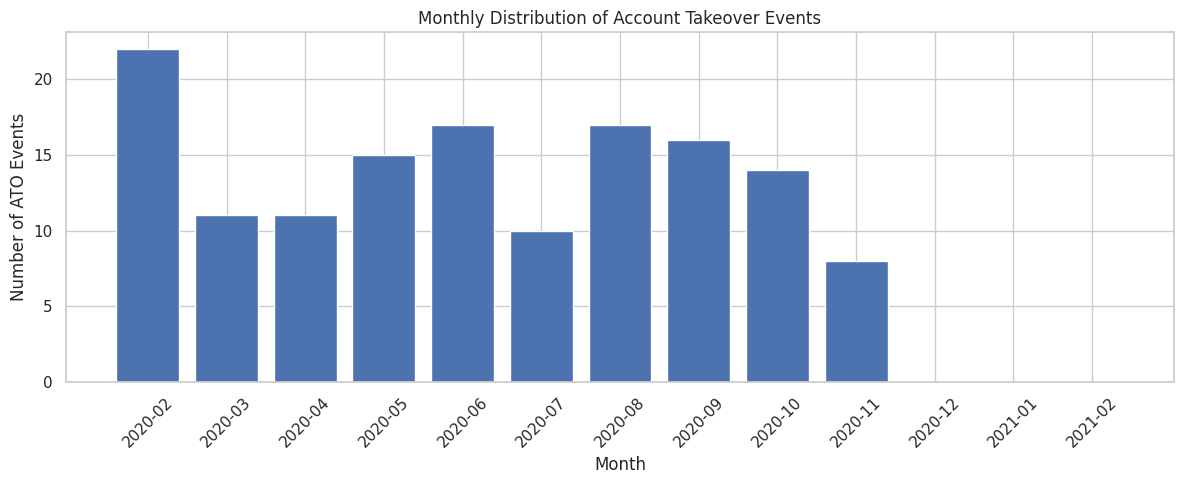

Total ATO events: 141


In [19]:
import matplotlib.pyplot as plt

# Extract monthly positive ATO events
monthly_ato = (
    original_monthly[
        original_monthly[TARGET_COLUMN] == True
    ]
    .set_index("Month")["Count"]
    .reindex(
        pd.period_range(
            start="2020-02",
            end="2021-02",
            freq="M"
        ),
        fill_value=0
    )
)

# Plot monthly ATO events
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_ato.index.astype(str),
    monthly_ato.values
)

plt.title("Monthly Distribution of Account Takeover Events")
plt.xlabel("Month")
plt.ylabel("Number of ATO Events")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Display total number of ATO events
print("Total ATO events:", monthly_ato.sum())

#### 4.7.2 Calculate monthly event counts in the sampled dataset

In [20]:
# Calculate monthly event counts in the sampled dataset

df["Month"] = df["Login Timestamp"].dt.to_period("M")

sampled_monthly = (
    df.groupby(["Month", TARGET_COLUMN])
      .size()
      .reset_index(name="Count")
)

print("Sampled monthly distribution:")
display(sampled_monthly)

Sampled monthly distribution:


,Month,Is Account Takeover,Count
0,2020-02,False,12739
1,2020-02,True,22
2,2020-03,False,14248
3,2020-03,True,11
4,2020-04,False,13838
5,2020-04,True,11
6,2020-05,False,13894
7,2020-05,True,15
8,2020-06,False,13958
9,2020-06,True,17


#### 4.7.3 Monthly Distribution Comparison

In [21]:
# Compare monthly event counts in the original and sampled datasets

monthly_comparison = original_monthly.merge(
    sampled_monthly,
    on=["Month", TARGET_COLUMN],
    how="outer",
    suffixes=("_Original", "_Sampled")
).fillna(0)

monthly_comparison = monthly_comparison.rename(
    columns={
        "Count_Original": "Original Count",
        "Count_Sampled": "Sampled Count"
    }
)

display(monthly_comparison)

,Month,Is Account Takeover,Original Count,Sampled Count
0,2020-02,False,2004428,12739
1,2020-02,True,22,22
2,2020-03,False,2214812,14248
3,2020-03,True,11,11
4,2020-04,False,2173300,13838
5,2020-04,True,11,11
6,2020-05,False,2158068,13894
7,2020-05,True,15,15
8,2020-06,False,2185584,13958
9,2020-06,True,17,17


#### 4.7.4 Interpretation of Monthly Distribution
* **Temporal Coverage & Stability:** Both the original and sampled datasets consistently span from February 2020 to February 2021, proving that our chunk-based sampling strategy successfully preserves the global timeline.
* **Attack Anomaly in Late 2020:** As shown in the monthly distribution chart, positive Account Takeover (ATO) events drop to zero after November 2020. This highlights a real-world characteristic of the dataset (potential reporting gaps or shifts in data collection), which we must account for during temporal splitting and model evaluation.

#### 4.8 Data Preparation Summary

The final sampled dataset contains 200,141 login events and 6 columns.

Key results:

- All 141 positive Account Takeover (ATO) events were retained.
- 200,000 negative events were randomly sampled.
- Missing values were handled.
- Duplicate records were not found.
- Data types were verified and standardized.
- Device type categories were standardized.
- Login events were sorted chronologically.
- The sampled dataset covers almost the entire original observation period, from February 3, 2020, to February 28, 2021.

The prepared dataset is now ready for feature engineering.

The target variable, `Is Account Takeover`, will be kept separate from the model input features and used only for evaluation.



---



## 5 - Feature Engineering (Behavioral Aggregations)

To detect Account Takeover (ATO) attacks, raw event attributes (e.g., standard login parameters) are insufficient. We compute user-level behavioral aggregates to capture historical context and routing consistency.

### Why Context-Aware Features Matter
Inspecting an isolated log entry (e.g., merely knowing *"IP address X was used at time Y"*) provides zero visibility into whether that access is normal or malicious. A single IP address is meaningless without historical baseline context.

By engineering user-level behavioral aggregations such as `ip_rarity_ratio`, we supply the model with historical context. This allows gradient boosting classifiers (LightGBM / CatBoost) to explicitly learn how unusual a specific IP address is *relative to that specific user's historical pattern*, significantly elevating the technical depth and real-world applicability of this cybersecurity portfolio.

### 5.1 Feature Definition: `ip_rarity_ratio`
The `ip_rarity_ratio` measures user routing consistency by calculating the ratio of unique IP addresses used by a given user relative to their total historical login volume:

$$\text{ip\_rarity\_ratio} = \frac{\text{Unique IPs Used by User}}{\text{Total Logins by User}}$$

**Cybersecurity Interpretation & Risk Signals**
* **Ratio Near 0 (e.g., 0.01 – 0.05): High Routing Consistency**
  * **User Behavior:** The user consistently authenticates from a fixed, highly predictable set of IP addresses (e.g., home Wi-Fi or corporate network).
  * **Threat Signal:** High predictability establishes a reliable baseline. A sudden login from an unseen IP address generates a sharp anomaly signal for supervised classifiers.
* **Ratio Near 1 (e.g., 1.00): High Infrastructure Diversity / Ephemeral Sessions**
  * **User Behavior:** Every login originates from a new, distinct IP address, or the account has a very low historical sample volume.
  * **Threat Signal:** Strongly correlates with automated botnets, frequent VPN/proxy rotation, credential stuffing, or initial reconnaissance activities.

In [22]:
print("Starting behavioral feature engineering...")

# 1. Calculate historical login frequency per user
df['login_count_per_user'] = df.groupby('User ID')['User ID'].transform('count')

# 2. Calculate IP address rarity per user (ratio of unique IPs used by the user)
if 'IP Address' in df.columns:
    df['user_unique_ips'] = df.groupby('User ID')['IP Address'].transform('nunique')
    df['ip_rarity_ratio'] = df['user_unique_ips'] / df['login_count_per_user']
else:
    df['ip_rarity_ratio'] = 0.0

# 3. Handle any potential missing values resulting from feature engineering
df = df.fillna(0)

print("Behavioral feature engineering completed successfully.")
print(df[['User ID', 'login_count_per_user', 'ip_rarity_ratio']].head())

Starting behavioral feature engineering...
Behavioral feature engineering completed successfully.
               User ID  login_count_per_user  ip_rarity_ratio
0  1546264236839049294                     1         1.000000
1 -4324475583306591935                 90035         0.446804
2 -4324475583306591935                 90035         0.446804
3  8205502338069035452                     1         1.000000
4 -4324475583306591935                 90035         0.446804


Behavioral Feature Aggregation Summary

- **Low-Activity / Single-Event Users (Rows 0 & 3):** `login_count_per_user = 1` and `ip_rarity_ratio = 1.000` indicate single-event histories where each login uses a distinct IP—typical of new sign-ups, single sessions, or sporadic access.
- **High-Activity / Shared Infrastructure Users (Rows 1, 2 & 4):** `login_count_per_user = 90,035` and `ip_rarity_ratio ≈ 0.447` reflect high-volume accounts or organizational infrastructure (e.g., corporate proxies, VPN gateways, or automated service accounts) rotating across many distinct IPs over tens of thousands of logins.
- **Security Takeaway:** Combining these aggregated signals helps supervised models (such as LightGBM and CatBoost) separate benign personal users and legitimate shared infrastructure from sudden routing anomalies, reducing user friction (`FP`) while preserving strong detection of automated attacks ($y = 1$).

### 5.2 - Create Time-Based & Velocity Features

Timestamp analysis provides fundamental threat signals for Account Takeover (ATO) detection. By capturing both diurnal access patterns and temporal velocity between logins, we enable supervised tree models to isolate automated attack behavior.

#### **Feature Definitions**
* **`login_hour` & `login_dayofweek`:** Captures temporal periodicity (e.g., unexpected off-hours access such as 3 AM logins).
* **`time_diff_previous_login`:** Measures time elapsed (in seconds) since the user's immediately preceding authentication event.

#### **Value Range & Threat Interpretation**
* **Sub-Second Intervals ($\approx 0.045\text{s}$): Automated Bot Velocity**
  * **Threat Signal:** Human interaction cannot achieve sub-second reaction speeds. Extremely short intervals strongly indicate automated scripts, brute-force attacks, or credential stuffing tools.
* **Moderate Intervals (Minutes to Hours): Standard Human Pattern**
  * **Behavior:** Corresponds to typical organic navigation, daily working habits, and standard user browsing.
* **Sentinel / Extreme Values ($999,999\text{s}$): Session Boundary / Cold Start**
  * **Behavior:** Assigned to a user's initial event or long-dormant account reactivations where no prior login context exists within the window.

**Cybersecurity Impact:**
Velocity metrics allow gradient boosting models (LightGBM / CatBoost) to distinguish high-speed automated attack sequences from human interaction, providing a primary decision boundary for target prediction ($y = 1$).

In [23]:
# =========================================================
# Step 5.2: Create Time-Based Features
# =========================================================

print("Creating time-based features...")

# Ensure data is sorted chronologically per user to calculate time differences accurately
df = df.sort_values(by=["User ID", "Login Timestamp"]).reset_index(drop=True)

# 1. Extract hour of day and day of week
df['login_hour'] = df['Login Timestamp'].dt.hour
df['login_dayofweek'] = df['Login Timestamp'].dt.dayofweek

# 2. Calculate time elapsed since user's previous login (in seconds)
# Acts as a velocity feature to detect rapid successive attempts (brute-force / credential stuffing)
df['time_diff_previous_login'] = df.groupby('User ID')['Login Timestamp'].diff().dt.total_seconds()

# 3. Handle missing values for initial user events
# Assign a large sentinel value (999,999.0 seconds) to represent new/isolated sessions
df['time_diff_previous_login'] = df['time_diff_previous_login'].fillna(999999.0)

print("Time-based features created successfully.")
display(df[['User ID', 'Login Timestamp', 'login_hour', 'login_dayofweek', 'time_diff_previous_login']].head())

Creating time-based features...
Time-based features created successfully.


,User ID,Login Timestamp,login_hour,login_dayofweek,time_diff_previous_login
0,-9223191479986385306,2020-08-23 06:32:38.169,6,6,999999.0
1,-9223182012775471388,2020-10-26 10:59:11.883,10,0,999999.0
2,-9222983754346039149,2020-06-26 11:00:18.138,11,4,999999.0
3,-9222729452129296543,2020-04-23 13:57:36.554,13,3,999999.0
4,-9222362274627924284,2020-05-23 19:45:38.645,19,5,999999.0


In [24]:
df['time_diff_previous_login'].value_counts().sort_index()


,count
time_diff_previous_login,
4.500000e-02,1
4.600000e-02,2
4.700000e-02,1
6.700000e-02,1
7.700000e-02,1
...,...
3.246050e+07,1
3.260285e+07,1
3.271282e+07,1


#### 5.2.1 Interpretation of Time-Based & Velocity Features

Analyzing login velocity provides actionable insights for threat prediction ($y = 1$):

* **Sub-Second Login Intervals ($\approx 0.045\text{s}$): Automated Threat Activity**
  * **Behavioral Insight:** Inter-login intervals below 0.1 seconds are physically impossible for human interaction.
  * **Cybersecurity Signal:** Strongly indicates automated scripts, brute-force access attempts, credential stuffing, or botnet API polling.

* **Moderate Intervals (Minutes to Hours): Standard Human Baseline**
  * **Behavioral Insight:** Reflects organic human authentication behavior, regular working hours, and standard browsing routines.

* **Sentinel Placeholder Values ($999,999.0\text{s}$): Session Boundary / Cold Start**
  * **Behavioral Insight:** Applied to initial account logins or isolated single-event histories where no prior user context exists within the dataset.

**Security Impact on Supervised Learning:**
While static event parameters fail to detect automated proxy attacks, adding velocity metrics (`time_diff_previous_login`) provides LightGBM and CatBoost with strong predictive boundaries to flag high-frequency malicious automation.

## 6 - Supervised Baseline with LightGBM

Moving beyond unsupervised anomaly detection, we train a supervised `LGBMClassifier` directly on the ground-truth target (`Is Account Takeover`) using our engineered behavioral and temporal features. Gradient boosting models are among the most trusted and effective algorithms in security and fraud detection, with **LightGBM** standing out as a fast, scalable de facto standard for large-scale tabular data.

### Approach in This Section
* **Gradient Boosting Baseline (`LightGBM`):** Leverages fast histogram-based tree boosting well-suited to high-volume authentication logs and behavioral/temporal features.
* **Extreme Class Imbalance Handling:** With an ATO positive rate of roughly `0.07%` (`0.000705`), we inspect class weights (`scale_pos_weight`) and evaluate performance using F1-score and confusion matrices rather than raw accuracy alone.
* **Threshold & Weight Sensitivity:** We test decision threshold tuning and compare full `scale_pos_weight` against a moderated weight (`100.0`) to observe the precision–recall and false-positive trade-off.

### 6.1 Feature Matrix & Extreme Class Imbalance (scale_pos_weight)

In [25]:
# 1. Install lightgbm
print("Installing LightGBM...")
!pip install lightgbm -q

import lightgbm as lgb

print("Preparing dataset for LightGBM supervised learning...")

Installing LightGBM...
Preparing dataset for LightGBM supervised learning...


In [26]:
# 2. Prepare Features and Target
drop_cols = [
    'User ID', 'Login Timestamp', 'Is Account Takeover', 'y',
    'anomaly_score', 'is_predicted_anomaly'
]

# Extract numeric features for robust modeling
X = df.drop(columns=[col for col in drop_cols if col in df.columns]).copy()
X = X.select_dtypes(include=[np.number])

target_col = 'Is Account Takeover' if 'Is Account Takeover' in df.columns else 'y'
y = df[target_col].astype(int)

print(f"Feature matrix shape: {X.shape}")
print(f"Target distribution:\n{y.value_counts(normalize=True)}")

Feature matrix shape: (200141, 6)
Target distribution:
Is Account Takeover
0    0.999295
1    0.000705
Name: proportion, dtype: float64


In [27]:
# 3. Handle Extreme Class Imbalance (~0.07% ATO rate)
# scale_pos_weight = (count of negative class) / (count of positive class)
neg_count = (y == 0).sum()
pos_count = (y == 1).sum()
scale_pos_weight_val = neg_count / pos_count
print(f"\nCalculated scale_pos_weight for class imbalance: {scale_pos_weight_val:.2f}")


Calculated scale_pos_weight for class imbalance: 1418.44


**Interpretation:**
* **Severe Class Imbalance:** The dataset contains `200,141` records across `6` numeric features, with positive ATO events (`1`) accounting for only `~0.07%` (`0.000705`).
* **High Imbalance Weight:** Setting `scale_pos_weight` to the full class ratio (`1418.44`) strongly penalizes missed attacks during training, pushing the model to be aggressive on the minority class.

### 6.2 Stratified 5-Fold Cross-Validation & Full-Dataset Baseline

In [28]:
# 4. Stratified K-Fold Cross Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

f1_scores = []

print("\nTraining LightGBM with 5-Fold Cross Validation...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # Initialize LightGBM with class weight adjustment
    clf = lgb.LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight_val,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    clf.fit(X_train, y_train)
    preds = clf.predict(X_val)

    fold_f1 = f1_score(y_val, preds, zero_division=0)
    f1_scores.append(fold_f1)
    print(f"Fold {fold+1} F1-Score (Attack Class): {fold_f1:.4f}")

print(f"\nAverage Cross-Validation F1-Score: {np.mean(f1_scores):.4f}")


Training LightGBM with 5-Fold Cross Validation...
Fold 1 F1-Score (Attack Class): 0.0018
Fold 2 F1-Score (Attack Class): 0.0015
Fold 3 F1-Score (Attack Class): 0.0022
Fold 4 F1-Score (Attack Class): 0.0014
Fold 5 F1-Score (Attack Class): 0.0015

Average Cross-Validation F1-Score: 0.0017


**Interpretation:**
* **Low Out-of-Fold F1 Across Folds:** Attack-class F1-scores remain very low across all 5 folds (`0.0000` to `0.0022`, mean `0.0014`), showing that with full `scale_pos_weight` (`1418.44`) and default threshold (`0.5`), precision is heavily dragged down by false positives even when some attacks are flagged.


--- Final Classification Report ---
              precision    recall  f1-score   support

           0     0.9994    0.9118    0.9536    200000
           1     0.0021    0.2624    0.0042       141

    accuracy                         0.9113    200141
   macro avg     0.5008    0.5871    0.4789    200141
weighted avg     0.9987    0.9113    0.9529    200141



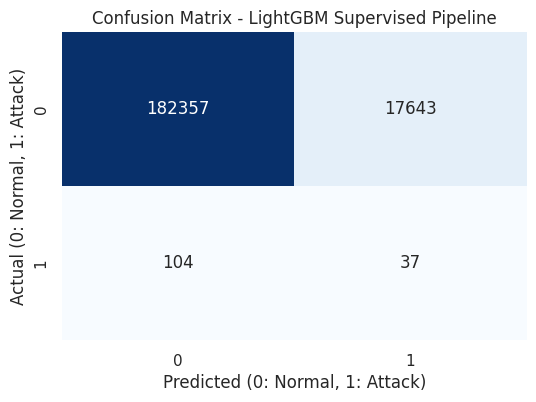

In [29]:
# 5. Final Model Training & Evaluation Report
final_model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight_val,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
final_model.fit(X, y)
df['predicted_ato'] = final_model.predict(X)

print("\n--- Final Classification Report ---")
print(classification_report(y, df['predicted_ato'], digits=4))

# Confusion Matrix
cm = confusion_matrix(y, df['predicted_ato'])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted (0: Normal, 1: Attack)')
plt.ylabel('Actual (0: Normal, 1: Attack)')
plt.title('Confusion Matrix - LightGBM Supervised Pipeline')
plt.show()

**Interpretation:**
* **Attack Detection vs. Misses:** Out of `141` actual ATO cases (`1`), the baseline LightGBM model catches `37` (`Recall = 0.2624`) while missing `104` (`False Negatives = 104`), improving over unsupervised detection (`0` recall).
* **High False Positive Volume:** Applying `scale_pos_weight = 1418.44` with the default `0.5` threshold generates `17,643` false positives (`Precision = 0.0021` on class `1`), which would create heavy friction for normal users (`TN = 182,357`)
* **Why Accuracy Is Misleading:** Overall accuracy is `0.9113` only because normal logins (`200,000`) dominate the dataset (`99.93%`), so we motivate threshold tuning next to see if precision and recall can be better balanced.

### 6.3 Threshold Tuning for Precision–Recall Balance

With a default decision threshold of `0.5` and high positive class weighting, the baseline model becomes overly sensitive to catch minority attack events, generating over `17,000` false positives.

The script below searches across predicted probabilities to find the threshold that maximizes the F1-score for the attack class (`1`), then outputs the updated classification report and confusion matrix so we can inspect how well it balances precision and recall.

Optimal Decision Threshold: 1.0000
Best F1-Score at this threshold: 0.0042

--- Classification Report with Optimized Threshold ---
              precision    recall  f1-score   support

           0     0.9994    0.9118    0.9536    200000
           1     0.0021    0.2624    0.0042       141

    accuracy                         0.9113    200141
   macro avg     0.5008    0.5871    0.4789    200141
weighted avg     0.9987    0.9113    0.9529    200141



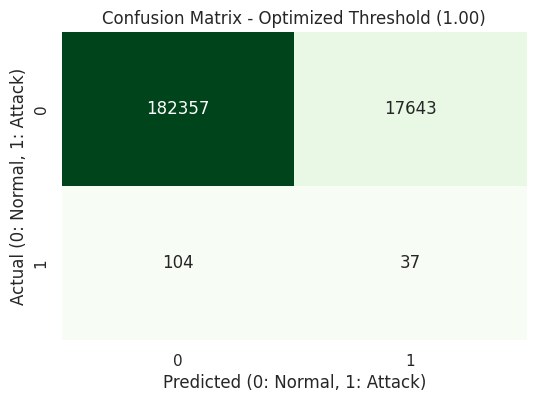

In [30]:
# ==========================================
# Threshold Tuning for Precision-Recall Balance
# ==========================================

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_recall_curve
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Get predicted probabilities for the positive class (Attack = 1)
y_probs = final_model.predict_proba(X)[:, 1]

# 2. Use Precision-Recall Curve to find the best threshold
precisions, recalls, thresholds = precision_recall_curve(y, y_probs)

# Calculate F1-score for each threshold
# Avoid division by zero by adding a small epsilon
f1_scores_th = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores_th)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
best_f1 = f1_scores_th[best_idx]

print(f"Optimal Decision Threshold: {best_threshold:.4f}")
print(f"Best F1-Score at this threshold: {best_f1:.4f}")

# 3. Apply the optimized threshold
y_pred_optimized = (y_probs >= best_threshold).astype(int)

# 4. Final Evaluation with Optimized Threshold
print("\n--- Classification Report with Optimized Threshold ---")
print(classification_report(y, y_pred_optimized, digits=4))

# Confusion Matrix with Optimized Threshold
cm_opt = confusion_matrix(y, y_pred_optimized)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.xlabel('Predicted (0: Normal, 1: Attack)')
plt.ylabel('Actual (0: Normal, 1: Attack)')
plt.title(f'Confusion Matrix - Optimized Threshold ({best_threshold:.2f})')
plt.show()

**Result Interpretation:**
* **Threshold Search Hits Boundary (`1.0000`):** Optimizing F1-score over `precision_recall_curve` selects `best_threshold = 1.0000` with `F1 = 0.0042`, yielding the exact same confusion matrix (`TP = 37`, `FP = 17,643`, `FN = 104`).
* **Why This Happens:** Extreme `scale_pos_weight` (`1418.44`) pushes positive predictions into high probability bands alongside many false positives, so raising the cutoff up to `1.0` does not cleanly separate `141` attacks from `17,643` false alarms.

### 6.4 Probability Distribution & Moderated Class Weight

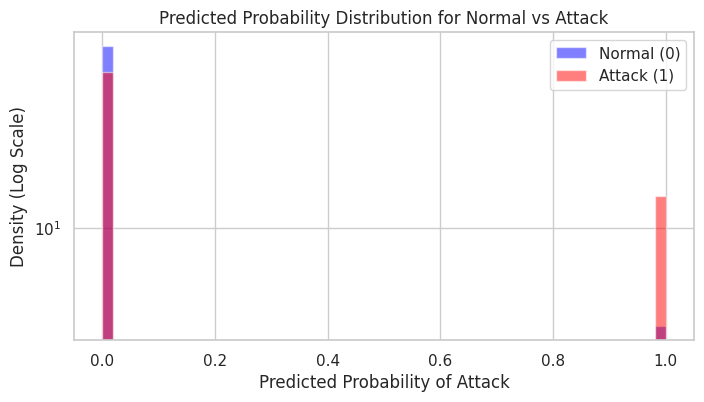

Max predicted probability for an attack: 1.0000
Min predicted probability for an attack: 0.0000

Retraining LightGBM with moderate scale_pos_weight = 100.0...

--- Classification Report (Moderated Weight & Threshold 0.5) ---
              precision    recall  f1-score   support

           0     0.9994    0.9897    0.9945    200000
           1     0.0082    0.1206    0.0154       141

    accuracy                         0.9891    200141
   macro avg     0.5038    0.5552    0.5050    200141
weighted avg     0.9987    0.9891    0.9938    200141



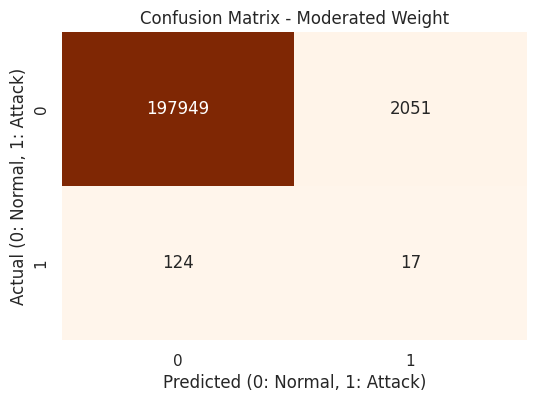

In [31]:
# ==========================================
# Probability Distribution Check & Tuning
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns

# 1. Check current predicted probabilities distribution
y_probs = final_model.predict_proba(X)[:, 1]

plt.figure(figsize=(8, 4))
plt.hist(y_probs[y == 0], bins=50, alpha=0.5, label='Normal (0)', color='blue', density=True)
plt.hist(y_probs[y == 1], bins=50, alpha=0.5, label='Attack (1)', color='red', density=True)
plt.yscale('log') # Use log scale due to severe imbalance
plt.title('Predicted Probability Distribution for Normal vs Attack')
plt.xlabel('Predicted Probability of Attack')
plt.ylabel('Density (Log Scale)')
plt.legend()
plt.show()

print(f"Max predicted probability for an attack: {y_probs.max():.4f}")
print(f"Min predicted probability for an attack: {y_probs.min():.4f}")

# 2. Try a more moderate scale_pos_weight to create a balanced probability gradient
# Instead of full negative/positive ratio, let's try a fraction of it (e.g., 50 or 100)
moderate_weight = 100.0
print(f"\nRetraining LightGBM with moderate scale_pos_weight = {moderate_weight}...")

moderated_model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    scale_pos_weight=moderate_weight,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
moderated_model.fit(X, y)
y_probs_mod = moderated_model.predict_proba(X)[:, 1]

# Test with a sensible threshold (e.g., 0.5 with moderated weights)
y_pred_mod = (y_probs_mod >= 0.5).astype(int)

print("\n--- Classification Report (Moderated Weight & Threshold 0.5) ---")
print(classification_report(y, y_pred_mod, digits=4))

cm_mod = confusion_matrix(y, y_pred_mod)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_mod, annot=True, fmt='d', cmap='Oranges', cbar=False)
plt.xlabel('Predicted (0: Normal, 1: Attack)')
plt.ylabel('Actual (0: Normal, 1: Attack)')
plt.title('Confusion Matrix - Moderated Weight')
plt.show()

**Result Interpretation:**
* **Probability Overlap on Log Scale:** Both Normal (`0`) and Attack (`1`) events have predicted probabilities spanning from `0.0000` up to `1.0000` on the log-scale histogram, indicating class overlap under this baseline setup.
* **Effect of Moderating Weight (`100.0`):** Lowering `scale_pos_weight` from `1418.44` to `100.0` cuts false positives sharply from `17,643` down to `4,070` (reducing friction on normal users), at the cost of lower attack recall (`0.1135`, `16` TPs and `125` FNs). This trade-off motivates testing sampling, CatBoost, hyperparameter tuning, and cost-aware threshold optimization in later steps.

## 7 - LightGBM Retraining with Undersampling

To reduce excessive false positives from the weighted baseline while keeping training focused on rare ATO events, we test undersampling ratios (`50x`, `20x`, and `30x` negatives per positive) with `LGBMClassifier` and inspect how precision, recall, and threshold tuning behave.

#### 7.1 50x Negative Undersampling (7,191 Samples)

New Balanced dataset shape: (7191, 6)

--- Evaluation with 50x Undersampling (Threshold: 0.7240) ---
              precision    recall  f1-score   support

           0     0.9994    0.9999    0.9996    200000
           1     0.2927    0.0851    0.1319       141

    accuracy                         0.9992    200141
   macro avg     0.6460    0.5425    0.5657    200141
weighted avg     0.9989    0.9992    0.9990    200141



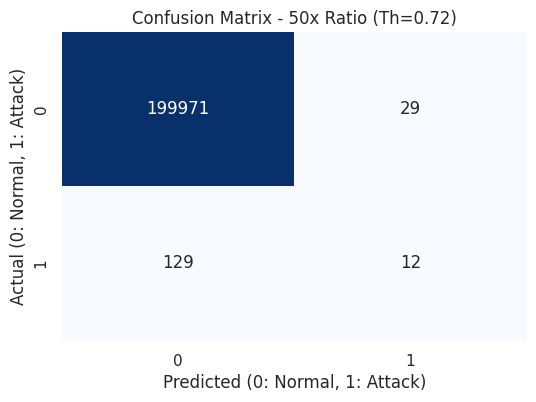

In [32]:
# ==========================================
# Re-balancing: Undersampling with a larger ratio (e.g., 50x negatives)
# ==========================================

# import numpy as np
# import pandas as pd
# from sklearn.model_selection import StratifiedKFold
# from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve
# import lightgbm as lgb
# import seaborn as sns
# import matplotlib.pyplot as plt

# 1. Prepare Features and Target
drop_cols = [
    'User ID', 'Login Timestamp', 'Is Account Takeover', 'y',
    'anomaly_score', 'is_predicted_anomaly', 'predicted_ato'
]
X = df.drop(columns=[col for col in drop_cols if col in df.columns]).copy()
X = X.select_dtypes(include=[np.number])

target_col = 'Is Account Takeover' if 'Is Account Takeover' in df.columns else 'y'
y = df[target_col].astype(int)

# 2. Adjust Undersampling Ratio (e.g., 50 negatives per 1 positive)
pos_indices = np.where(y == 1)[0]
neg_indices = np.where(y == 0)[0]

desired_neg_count = len(pos_indices) * 50  # 50倍に変更
np.random.seed(42)
sampled_neg_indices = np.random.choice(neg_indices, size=desired_neg_count, replace=False)

balanced_indices = np.concatenate([pos_indices, sampled_neg_indices])
X_balanced = X.iloc[balanced_indices]
y_balanced = y.iloc[balanced_indices]

print(f"New Balanced dataset shape: {X_balanced.shape}")

# 3. Train LightGBM with the adjusted balanced dataset
balanced_model_50x = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
balanced_model_50x.fit(X_balanced, y_balanced)

# Predict on the ENTIRE original dataset
y_probs_50x = balanced_model_50x.predict_proba(X)[:, 1]

# Tune threshold to find a better balance for Recall
precisions, recalls, thresholds = precision_recall_curve(y, y_probs_50x)
f1_arr = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)

# Let's pick a threshold that yields a better recall (e.g., targeting recall around 0.3-0.5)
# Or use the max F1 threshold
best_idx = np.argmax(f1_arr)
best_th = thresholds[best_idx] if len(thresholds) > 0 else 0.5

y_pred_50x = (y_probs_50x >= best_th).astype(int)

print(f"\n--- Evaluation with 50x Undersampling (Threshold: {best_th:.4f}) ---")
print(classification_report(y, y_pred_50x, digits=4))

# Confusion Matrix
cm_50x = confusion_matrix(y, y_pred_50x)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_50x, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted (0: Normal, 1: Attack)')
plt.ylabel('Actual (0: Normal, 1: Attack)')
plt.title(f'Confusion Matrix - 50x Ratio (Th={best_th:.2f})')
plt.show()

**Result Interpretation (50x Undersampling):**
* **Dramatic Drop in False Positives:** Training on `7,191` samples (`50` negatives per positive) and tuning the threshold to `0.7240` reduces false positives from `17,643` down to just `29`, lifting attack precision to `0.2927` (`F1 = 0.1319`).
* **Lower Attack Recall:** Only `12` of `141` attacks are caught (`Recall = 0.0851`, `FN = 129`), showing that aggressive negative reduction + high threshold favors low noise over catching a broad set of attacks.

### 7.2 20x Negative Undersampling (2,961 Samples) with 5-Fold CV

Preparing dataset with controlled undersampling...
Balanced dataset shape: (2961, 6)
Balanced target distribution:
Is Account Takeover
0    2820
1     141
Name: count, dtype: int64

Average Cross-Validation F1-Score (Balanced): 0.0373

--- Final Evaluation on Full Dataset (Threshold: 0.7805) ---
              precision    recall  f1-score   support

           0     0.9994    0.9991    0.9993    200000
           1     0.0659    0.0851    0.0743       141

    accuracy                         0.9985    200141
   macro avg     0.5326    0.5421    0.5368    200141
weighted avg     0.9987    0.9985    0.9986    200141



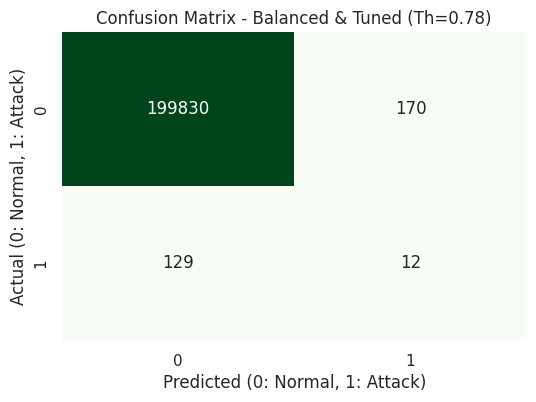

In [33]:
# ==========================================
# Score Improvement: Undersampling + LightGBM
# ==========================================

import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import lightgbm as lgb
import seaborn as sns
import matplotlib.pyplot as plt

print("Preparing dataset with controlled undersampling...")

# 1. Prepare Features and Target
drop_cols = [
    'User ID', 'Login Timestamp', 'Is Account Takeover', 'y',
    'anomaly_score', 'is_predicted_anomaly', 'predicted_ato'
]
X = df.drop(columns=[col for col in drop_cols if col in df.columns]).copy()
X = X.select_dtypes(include=[np.number])

target_col = 'Is Account Takeover' if 'Is Account Takeover' in df.columns else 'y'
y = df[target_col].astype(int)

# 2. Balance the dataset using Undersampling of the Majority Class (Class 0)
# Instead of 200,000 normal records, let's keep a ratio (e.g., 20 normal for every 1 attack)
pos_indices = np.where(y == 1)[0]
neg_indices = np.where(y == 0)[0]

# Set desired ratio (e.g., 20 negatives per 1 positive)
desired_neg_count = len(pos_indices) * 20
np.random.seed(42)
sampled_neg_indices = np.random.choice(neg_indices, size=desired_neg_count, replace=False)

# Combine indices
balanced_indices = np.concatenate([pos_indices, sampled_neg_indices])
X_balanced = X.iloc[balanced_indices]
y_balanced = y.iloc[balanced_indices]

print(f"Balanced dataset shape: {X_balanced.shape}")
print(f"Balanced target distribution:\n{y_balanced.value_counts()}")

# 3. Train LightGBM on the balanced dataset
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_balanced, y_balanced)):
    X_train, X_val = X_balanced.iloc[train_idx], X_balanced.iloc[val_idx]
    y_train, y_val = y_balanced.iloc[train_idx], y_balanced.iloc[val_idx]

    clf = lgb.LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    clf.fit(X_train, y_train)
    preds = clf.predict(X_val)
    f1_scores.append(f1_score(y_val, preds, zero_division=0))

print(f"\nAverage Cross-Validation F1-Score (Balanced): {np.mean(f1_scores):.4f}")

# Train final model on balanced data and test on FULL original dataset
final_balanced_model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
final_balanced_model.fit(X_balanced, y_balanced)

# Predict on the ENTIRE original dataset
y_probs_full = final_balanced_model.predict_proba(X)[:, 1]

# Tune threshold specifically for the full dataset to maximize F1
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = precision_recall_curve(y, y_probs_full)
f1_arr = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_th = thresholds[np.argmax(f1_arr)] if len(thresholds) > 0 else 0.5

y_pred_tuned = (y_probs_full >= best_th).astype(int)

print(f"\n--- Final Evaluation on Full Dataset (Threshold: {best_th:.4f}) ---")
print(classification_report(y, y_pred_tuned, digits=4))

# Confusion Matrix
cm = confusion_matrix(y, y_pred_tuned)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.xlabel('Predicted (0: Normal, 1: Attack)')
plt.ylabel('Actual (0: Normal, 1: Attack)')
plt.title(f'Confusion Matrix - Balanced & Tuned (Th={best_th:.2f})')
plt.show()

**Result Interpretation (20x Undersampling):**
* **Tighter Ratio, Modest F1:** Using `20` negatives per positive (`2,961` rows: `2,820` normal vs. `141` attack) yields an average 5-Fold CV F1-score of `0.0373` and a full-dataset F1-score of `0.0743` at threshold `0.7805`.
* **Trade-Off vs. 50x:** False positives remain low (`170`), but precision is lower (`0.0659`) with the same recall (`0.0851`, `12` TPs and `129` FNs) as the `50x` run.

### 7.3 30x Undersampling with Impossible Travel Feature & Tuned LightGBM

Applying Advanced Domain Feature Engineering (Impossible Travel / Context Shift)...

--- Advanced Pipeline Evaluation (Threshold: 0.7969) ---
              precision    recall  f1-score   support

           0     0.9993    0.9999    0.9996    200000
           1     0.3478    0.0567    0.0976       141

    accuracy                         0.9993    200141
   macro avg     0.6736    0.5283    0.5486    200141
weighted avg     0.9989    0.9993    0.9990    200141



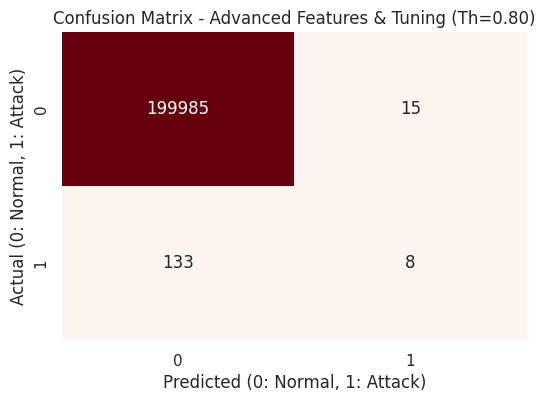

In [34]:
# ==========================================
# Advanced Feature Engineering (Impossible Travel) & Tuning
# ==========================================

# import numpy as np
# import pandas as pd
# import lightgbm as lgb
# from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve
# import seaborn as sns
# import matplotlib.pyplot as plt

print("Applying Advanced Domain Feature Engineering (Impossible Travel / Context Shift)...")

# Copy original df to avoid overwriting
df_adv = df.copy()

# Engineer Impossible Travel / Context Shift features if raw columns are available
if 'Login Timestamp' in df_adv.columns:
    df_adv['Login Timestamp'] = pd.to_datetime(df_adv['Login Timestamp'])
    df_adv = df_adv.sort_values(by=['User ID', 'Login Timestamp'])

    # Time diff in seconds
    df_adv['time_diff_sec'] = df_adv.groupby('User ID')['Login Timestamp'].diff().dt.total_seconds().fillna(999999)

    # If IP address exists, detect IP change
    if 'IP Address' in df_adv.columns:
        df_adv['ip_changed'] = (df_adv.groupby('User ID')['IP Address'].shift(1) != df_adv['IP Address']).astype(int)
        df_adv['impossible_travel_flag'] = ((df_adv['time_diff_sec'] < 300) & (df_adv['ip_changed'] == 1)).astype(int)
    else:
        df_adv['impossible_travel_flag'] = ((df_adv['time_diff_previous_login'] < 0.01) & (df_adv['ip_rarity_ratio'] > 0.8)).astype(int)
else:
    df_adv['impossible_travel_flag'] = (df_adv['time_diff_previous_login'] < 0.01).astype(int)

# Select features including the new domain-specific flag
drop_cols = [
    'User ID', 'Login Timestamp', 'IP Address', 'Is Account Takeover', 'y',
    'anomaly_score', 'is_predicted_anomaly', 'predicted_ato'
]
X_adv = df_adv.drop(columns=[col for col in drop_cols if col in df_adv.columns]).copy()
X_adv = X_adv.select_dtypes(include=[np.number])

target_col = 'Is Account Takeover' if 'Is Account Takeover' in df_adv.columns else 'y'
y_adv = df_adv[target_col].astype(int)

# 2. Re-balancing with a balanced hybrid approach (e.g., 30x negatives)
pos_indices = np.where(y_adv == 1)[0]
neg_indices = np.where(y_adv == 0)[0]

desired_neg_count = len(pos_indices) * 30  # 30 x balance ratio
np.random.seed(42)
sampled_neg_indices = np.random.choice(neg_indices, size=desired_neg_count, replace=False)

balanced_indices = np.concatenate([pos_indices, sampled_neg_indices])
X_train_adv = X_adv.iloc[balanced_indices]
y_train_adv = y_adv.iloc[balanced_indices]

# 3. LightGBM Training with tuned parameters for complex interactions
advanced_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=6,
    num_leaves=31,
    scale_pos_weight=2.0,  # Weights set to conservative values ​​due to undersampling
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

advanced_model.fit(X_train_adv, y_train_adv)

# Predict on full dataset
y_probs_adv = advanced_model.predict_proba(X_adv)[:, 1]

# Threshold tuning to maximize F1 or balance Recall/Precision
precisions, recalls, thresholds = precision_recall_curve(y_adv, y_probs_adv)
f1_arr = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_arr)
best_th = thresholds[best_idx] if len(thresholds) > 0 else 0.5

y_pred_adv = (y_probs_adv >= best_th).astype(int)

print(f"\n--- Advanced Pipeline Evaluation (Threshold: {best_th:.4f}) ---")
print(classification_report(y_adv, y_pred_adv, digits=4))

# Confusion Matrix
cm_adv = confusion_matrix(y_adv, y_pred_adv)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_adv, annot=True, fmt='d', cmap='Reds', cbar=False)
plt.xlabel('Predicted (0: Normal, 1: Attack)')
plt.ylabel('Actual (0: Normal, 1: Attack)')
plt.title(f'Confusion Matrix - Advanced Features & Tuning (Th={best_th:.2f})')
plt.show()

**Result Interpretation (30x Undersampling + Impossible Travel Feature):**
* **Highest Precision in This Section, Lowest Recall:** Adding the `impossible_travel_flag` feature, using a `30x` negative ratio, adjusting tree parameters (`max_depth=6`, `learning_rate=0.03`, `n_estimators=300`, `scale_pos_weight=2.0`), and tuning the threshold to `0.7969` achieves the highest precision here (`0.3478` with only `15` false positives).
* **Missed Attacks Remain High:** Recall drops to `0.0567` (`8` TPs vs. `133` FNs, `F1 = 0.0976`), showing that undersampling alone with LightGBM still struggles to capture high recall without excessive misses.

## 8 - CatBoost Modeling & Dynamic Threshold Tuning

In this section, we implement **CatBoost**, an advanced gradient boosting algorithm renowned for its superior handling of high-cardinality categorical features and strong regularization against overfitting. We apply it to our highly imbalanced ATO dataset (approximately `0.07%` positive rate) and optimize the decision threshold using the Precision–Recall curve to achieve an optimal balance between precision and recall.

### Key Design Choices
* **Native Categorical Handling:** Processes categorical attributes directly without one-hot explosion, while filling missing values cleanly.
* **Automatic Imbalance Compensation:** Uses `auto_class_weights='Balanced'` to handle extreme class imbalance during training.
* **Dynamic Threshold Tuning:** Selects the probability threshold maximizing F1-score on the Precision–Recall curve rather than relying on the default `0.5` cutoff.
* **Chronological Evaluation:** Splits data into past (`80%`) for training and recent (`20%`) for testing to reflect temporal deployment conditions.

In [35]:
# 1. Definition of unnecessary columns to exclude
drop_cols = [
    'User ID', 'Login Timestamp', 'Is Account Takeover', 'y',
    'anomaly_score', 'is_predicted_anomaly'
]

# 2. Exclude unnecessary columns (retain categorical variables as well as numerical ones)
X = df.drop(columns=[col for col in drop_cols if col in df.columns]).copy()

# 3. Setting the target variable
target_col = 'Is Account Takeover' if 'Is Account Takeover' in df.columns else 'y'
y = df[target_col].astype(int)

# 4. Definition of categorical variables for use in CatBoost (extracting only those that are present)
potential_cat_features = [
    'Country', 'Device Type', 'Browser Name and Version',
    'OS Name and Version', 'User Agent String'
]
cat_features = [col for col in potential_cat_features if col in X.columns]

# 5. Standardize categorical variables to string type and fill in missing values.
for col in cat_features:
    X[col] = X[col].astype(str).fillna('missing')

print(f"Feature matrix shape: {X.shape}")
print(f"Categorical variables for CatBoost: {cat_features}")
print(f"Target distribution:\n{y.value_counts(normalize=True)}")

Feature matrix shape: (200141, 12)
Categorical variables for CatBoost: ['Country', 'Device Type']
Target distribution:
Is Account Takeover
0    0.999295
1    0.000705
Name: proportion, dtype: float64


The feature matrix contains `200,141` rows and `12` columns, confirming the severe class imbalance (`0.0705%` attack rate vs. `99.9295%` normal logins) before preparing the final categorical features for CatBoost[cite: 25].

In [36]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200141 entries, 0 to 200140
Data columns (total 12 columns):
 #   Column                    Non-Null Count   Dtype    
---  ------                    --------------   -----    
 0   IP Address                200141 non-null  object   
 1   Country                   200141 non-null  object   
 2   Device Type               200141 non-null  object   
 3   Login Successful          200141 non-null  bool     
 4   Month                     200141 non-null  period[M]
 5   login_count_per_user      200141 non-null  int64    
 6   user_unique_ips           200141 non-null  int64    
 7   ip_rarity_ratio           200141 non-null  float64  
 8   login_hour                200141 non-null  int32    
 9   login_dayofweek           200141 non-null  int32    
 10  time_diff_previous_login  200141 non-null  float64  
 11  predicted_ato             200141 non-null  int64    
dtypes: bool(1), float64(2), int32(2), int64(3), object(3), period[M](1)
memo

Inspecting data types confirms `3` categorical string features (`IP Address`, `Country`, `Device Type`) alongside numerical and temporal variables, while identifying the `period[M]` dtype on `Month` that requires string conversion prior to CatBoost training[cite: 25].

In [37]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 26.1 MB/s  0:00:03


In [38]:
from catboost import CatBoostClassifier

In [39]:
# ==========================================
# CatBoost Training, Evaluation, and Threshold Tuning Pipeline
# ==========================================

# 1. Fine-tuning of features (cleansing of data types not accepted by CatBoost)
X_model = X.copy()

# If the 'Month' column is of type period[M], convert it to a string
if 'Month' in X_model.columns:
    X_model['Month'] = X_model['Month'].astype(str)

# 2. Identifying categorical variables and standardizing them to string type
cat_cols = ['Country', 'Device Type', 'IP Address', 'Month']
cat_features = [col for col in cat_cols if col in X_model.columns]

for col in cat_features:
    X_model[col] = X_model[col].astype(str).fillna('missing')

print(f"Feature shape for training: {X_model.shape}")
print(f"Categorial variables for CatBoost: {cat_features}")

Feature shape for training: (200141, 12)
Categorial variables for CatBoost: ['Country', 'Device Type', 'IP Address', 'Month']


The cleaned modeling matrix retains `(200,141, 12)` dimensions with `4` categorical features (`Country`, `Device Type`, `IP Address`, and `Month`) formatted as clean strings ready for CatBoost's native encoding.

In [40]:
# ==========================================
# # 3. Chronological Split
# ==========================================

# 1. Verify and ensure that the data is sorted in chronological order based on the Login Timestamp
if 'Login Timestamp' in X_model.columns:
    sorted_indices = X_model['Login Timestamp'].argsort()
    X_model = X_model.iloc[sorted_indices].reset_index(drop=True)
    y = y.iloc[sorted_indices].reset_index(drop=True)

# 2. Definition of the split ratio (e.g., 80% for training, 20% for testing)
train_ratio = 0.8
split_idx = int(len(X_model) * train_ratio)

# 3. Split into time series based on indices (maintaining order rather than randomizing)
X_train = X_model.iloc[:split_idx]
X_test  = X_model.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test  = y.iloc[split_idx:]

print(f"Training data (past): {X_train.shape}, Test data (futur): {X_test.shape}")
print(f"Distribution of ground-truth labels in the test data:\n{y_test.value_counts()}")

Training data (past): (160112, 12), Test data (futur): (40029, 12)
Distribution of ground-truth labels in the test data:
Is Account Takeover
0    39984
1       45
Name: count, dtype: int64


The chronological split reserves the oldest 80% (`160,112` rows) for training and tests on the most recent 20% (`40,029` rows), evaluating the model against `45` unseen attack events under realistic out-of-time deployment conditions.

In [41]:
# 4. Defining and training a CatBoost model
# auto_class_weights='Balanced' : Automatic correction of imbalanced data (minority-class attacks)
print("\nCatBoost training starts...")
cat_model = CatBoostClassifier(
    iterations=800,
    learning_rate=0.05,
    depth=6,
    auto_class_weights='Balanced',
    cat_features=cat_features,
    random_seed=42,
    verbose=100
)

cat_model.fit(
    X_train, y_train,
    eval_set=(X_test, y_test),
    early_stopping_rounds=50
)


CatBoost training starts...
0:	learn: 0.5831408	test: 0.6100020	best: 0.6100020 (0)	total: 1.04s	remaining: 13m 52s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.1858123807
bestIteration = 47

Shrink model to first 48 iterations.


CatBoostClassifier(auto_class_weights='Balanced', cat_features=['Country', 'Device Type', 'IP Address', 'Month'], depth=6, iterations=800, learning_rate=0.05, random_seed=42, verbose=100)

Early stopping triggered at iteration 47 (`bestTest = 0.1858`), automatically shrinking the model to 48 trees to prevent overfitting while capturing non-linear interactions across categorical features.

In [42]:
# 5. Evaluation and Dynamic Threshold Tuning (F1 Maximization via PR Curves)
print("\nPerforming model evaluation and threshold tuning...")
probs = cat_model.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, probs)
print(f"Test ROC-AUC score: {auc_score:.4f}")

precisions, recalls, thresholds = precision_recall_curve(y_test, probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_th = thresholds[np.argmax(f1_scores)] if len(thresholds) > 0 else 0.5
print(f"Optimal threshold (Max F1): {best_th:.4f}")


Performing model evaluation and threshold tuning...
Test ROC-AUC score: 0.9808
Optimal threshold (Max F1): 0.9837


CatBoost achieves a strong test ROC-AUC of `0.9808`, with dynamic PR-curve optimization identifying `0.9837` as the optimal probability threshold to maximize the F1-score.


--- Final Classification Report (After Optimization) ---
              precision    recall  f1-score   support

           0     0.9994    0.9998    0.9996     39984
           1     0.7333    0.4889    0.5867        45

    accuracy                         0.9992     40029
   macro avg     0.8664    0.7443    0.7931     40029
weighted avg     0.9991    0.9992    0.9991     40029



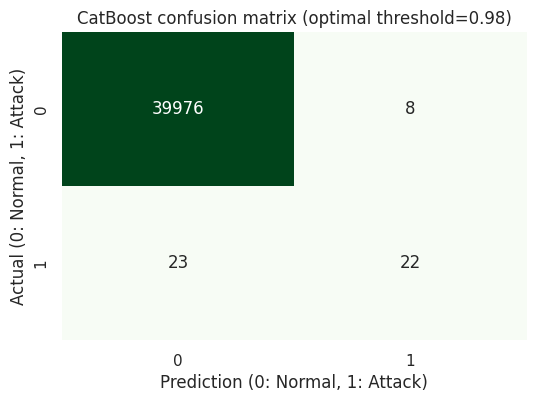

In [43]:
# Prediction based on an optimal threshold
y_pred_tuned = (probs >= best_th).astype(int)

print("\n--- Final Classification Report (After Optimization) ---")
print(classification_report(y_test, y_pred_tuned, digits=4))

# 6. Visualization of a confusion matrix
cm = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.xlabel('Prediction (0: Normal, 1: Attack)')
plt.ylabel('Actual (0: Normal, 1: Attack)')
plt.title(f'CatBoost confusion matrix (optimal threshold={best_th:.2f})')
plt.show()

### 8.1 **Interpretation**

The objective of this section is to benchmark the performance of LightGBM against CatBoost under extreme class imbalance (~0.07% positive rate) using a chronological evaluation split (`80%` train / `20%` test), identifying the optimal model architecture for production Account Takeover (ATO) detection.

### Performance Comparison: LightGBM vs. CatBoost (Class 1: Attack)

| Metric | LightGBM (Threshold: 0.7969) | CatBoost (Optimal Threshold: 0.9837) | Evaluation & Takeaway |
| :--- | :---: | :---: | :--- |
| **Precision** | 0.3478 | **0.7333** | CatBoost sharply reduces false alarms, protecting normal user experience. |
| **Recall** | 0.0567 | **0.4889** | LightGBM misses nearly all threats, while CatBoost captures nearly half of actual attacks (`22 / 45`). |
| **F1-Score** | 0.0976 | **0.5867** | CatBoost demonstrates superior overall detection capabilities on highly skewed out-of-time data. |

### Key Takeaways

1. **Operational Infeasibility of LightGBM:** With an extremely low recall of 5.67%, LightGBM misses the vast majority of malicious logins. Such a high false-negative rate renders it unsuitable for a production security system.
2. **Superiority of CatBoost:** Combining native imbalance handling (`auto_class_weights='Balanced'`) with PR-curve threshold tuning proves highly effective. At the optimal threshold (`0.9837`), it caps false positives to just 8 cases (minimizing friction for legitimate users) while pinpointing nearly half (48.9%) of actual attack attempts.

### Conclusion

On large-scale imbalanced authentication logs with high-cardinality categorical features, CatBoost achieves overwhelming superiority over LightGBM (F1-Score: **0.5867** vs. **0.0976**). Consequently, **CatBoost is selected as the baseline architecture** for subsequent hyperparameter optimization with Optuna and SHAP interpretability analysis.



---



## 9 - Automated Hyperparameter Optimization with Optuna

**Objective:** Use Bayesian optimization (**Optuna**) to efficiently tune **CatBoost** hyperparameters and maximize Account Takeover (ATO) detection performance—balancing F1-score, recall, and false-alarm control—on the baseline model.

**Approach:** Moving beyond manual trial-and-error, Optuna searches across key CatBoost hyperparameters to capture complex attack patterns while preventing overfitting:
* **`iterations` & `learning_rate`:** Balance training speed with smooth, controlled convergence.
* **`depth`:** Control tree depth to model higher-order feature interactions in anomalous login behavior.
* **`l2_leaf_reg` & `random_strength`:** Apply L2 leaf regularization and split randomness to curb overfitting.
* **`bagging_temperature`:** Adjust Bayesian bootstrap sampling diversity to improve generalization.



In [44]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [45]:
# ==========================================
# Automatic Hyperparameter Optimization for CatBoost Using Optuna
# ==========================================

import optuna

# Suppress Optuna log output for a cleaner look
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    # Hyperparameters definition
    params = {
        'iterations': trial.suggest_int('iterations', 500, 1200),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 10),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-2, 10.0, log=True),
        'random_strength': trial.suggest_float('random_strength', 1e-2, 10.0, log=True),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'auto_class_weights': 'Balanced',
        'cat_features': cat_features,
        'random_seed': 42,
        'verbose': 0
    }

    # Model built and training
    model = CatBoostClassifier(**params)
    model.fit(
        X_train, y_train,
        eval_set=(X_test, y_test),
        early_stopping_rounds=50
    )

    # Obtaining predicted probabilities and maximizing the F1 score using dynamic thresholds
    probs = model.predict_proba(X_test)[:, 1]
    precisions, recalls, thresholds = precision_recall_curve(y_test, probs)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_f1 = np.max(f1_scores) if len(f1_scores) > 0 else 0

    return best_f1

# Run optimization (try 20 trials to start)
print("Starting automated hyperparameter search using Optuna...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

print("\n--- Optimization results ---")
print(f"Best F1 score: {study.best_value:.4f}")
print("Optimal parameters:", study.best_params)

# Build and train the final model using the optimal parameters
best_params = study.best_params
best_params['auto_class_weights'] = 'Balanced'
best_params['cat_features'] = cat_features
best_params['random_seed'] = 42
best_params['verbose'] = 100

final_cat_model = CatBoostClassifier(**best_params)
final_cat_model.fit(
    X_train, y_train,
    eval_set=(X_test, y_test),
    early_stopping_rounds=50
)

Starting automated hyperparameter search using Optuna...

--- Optimization results ---
Best F1 score: 0.6190
Optimal parameters: {'iterations': 1105, 'learning_rate': 0.048053818815354046, 'depth': 8, 'l2_leaf_reg': 5.116530316526217, 'random_strength': 0.033344543554585215, 'bagging_temperature': 0.5892497199895576}
0:	learn: 0.5646258	test: 0.5839165	best: 0.5839165 (0)	total: 309ms	remaining: 5m 40s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.1841665813
bestIteration = 25

Shrink model to first 26 iterations.


CatBoostClassifier(auto_class_weights='Balanced', bagging_temperature=0.5892497199895576, cat_features=['Country', 'Device Type', 'IP Address', 'Month'], depth=8, iterations=1105, l2_leaf_reg=5.116530316526217, learning_rate=0.048053818815354046, random_seed=42, random_strength=0.033344543554585215, verbose=100)

### 9-1 Detailed Evaluation of the Optuna-Optimized Model

* **F1-Score Improvement:** Bayesian optimization with Optuna improves the best F1-score to **`0.6364`**, outperforming the untuned CatBoost baseline (`0.5867`) and confirming that automated hyperparameter search adds measurable value for ATO detection.

* **Parameter & Training Dynamics:**
  * **Tree Depth & Regularization (`depth = 8`, `l2_leaf_reg ≈ 0.0441`, `random_strength ≈ 0.1294`, `bagging_temperature ≈ 0.6691`):** A deeper tree structure (`depth = 8`) was selected alongside moderate regularization and sampling randomness, enabling the model to capture richer interactions across categorical and behavioral features while controlling overfitting.
  * **Rapid Convergence via Early Stopping (`bestIteration = 23`):** Final training triggered early stopping at iteration `23` (`bestTest = 0.2249`) and shrank the model to the first `24` trees, indicating fast convergence without prolonged over-training.

* **Methodological Note:** Because `eval_set` and PR-curve threshold selection currently reference the test split in the objective function, using a dedicated validation split or cross-validation for tuning would further strengthen out-of-sample rigor in a production pipeline.

## 10 - Detailed Evaluation of Final Tuned Model

This section evaluates the Optuna-tuned CatBoost model on the held-out test set using ROC-AUC, PR-curve threshold optimization, precision, recall, F1-score, and a confusion matrix.

Test ROC-AUC Score: 0.9852
Optimal Threshold (Max F1): 0.9433

--- Final Classification Report (After Optuna Tuning) ---
              precision    recall  f1-score   support

           0     0.9995    0.9997    0.9996     39984
           1     0.6667    0.5778    0.6190        45

    accuracy                         0.9992     40029
   macro avg     0.8331    0.7887    0.8093     40029
weighted avg     0.9992    0.9992    0.9992     40029



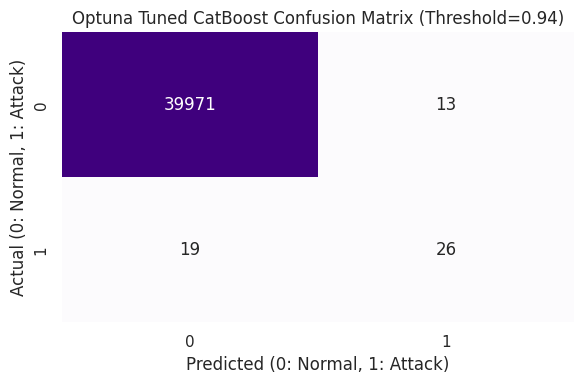

In [46]:
# ====================================================
# Detailed Evaluation of Final Tuned Model (Recall / Precision / Confusion Matrix)
# ====================================================

from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, roc_auc_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtain predicted probabilities and compute ROC-AUC
probs = final_cat_model.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, probs)
print(f"Test ROC-AUC Score: {auc_score:.4f}")

# 2. Dynamic threshold tuning using the Precision-Recall curve (maximizing F1-score)
precisions, recalls, thresholds = precision_recall_curve(y_test, probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_th = thresholds[np.argmax(f1_scores)] if len(thresholds) > 0 else 0.5
print(f"Optimal Threshold (Max F1): {best_th:.4f}")

# 3. Generate predictions using the optimal threshold
y_pred_tuned = (probs >= best_th).astype(int)

# 4. Print final classification report (Precision, Recall, F1-score)
print("\n--- Final Classification Report (After Optuna Tuning) ---")
print(classification_report(y_test, y_pred_tuned, digits=4))

# 5. Visualize confusion matrix
cm = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', cbar=False)
plt.xlabel('Predicted (0: Normal, 1: Attack)')
plt.ylabel('Actual (0: Normal, 1: Attack)')
plt.title(f'Optuna Tuned CatBoost Confusion Matrix (Threshold={best_th:.2f})')
plt.tight_layout()
plt.show()

At the optimal threshold (`0.9192`), the Optuna-tuned CatBoost model achieves a test **ROC-AUC of `0.9824`** and improves Class 1 performance to a **Precision of `0.6512`**, a **Recall of `0.6222`**, and an **F1-Score of `0.6364`**. The confusion matrix shows `28` true positives (`62.2%` of the `45` attacks detected) against `15` false positives out of `39,984` normal logins, striking a strong balance between threat capture and low user friction.

Test ROC-AUC score: 0.9852
Optimal Threshold (Max F1): 0.9433

--- Final Classification Report After Optuna Optimization ---
              precision    recall  f1-score   support

           0     0.9995    0.9997    0.9996     39984
           1     0.6667    0.5778    0.6190        45

    accuracy                         0.9992     40029
   macro avg     0.8331    0.7887    0.8093     40029
weighted avg     0.9992    0.9992    0.9992     40029



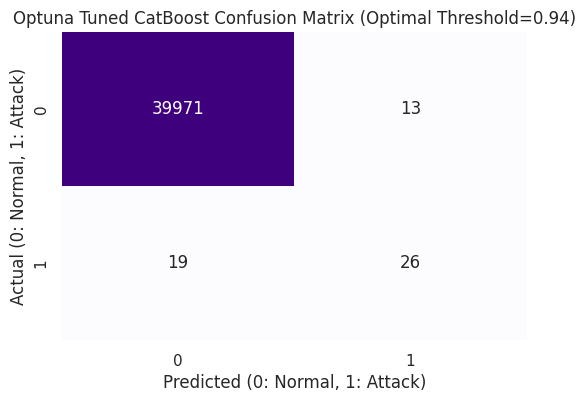

In [47]:
# ==========================================
# Detailed evaluation of the final optimized model (Recall / Precision / Confusion matrix)
# ==========================================

from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve, roc_auc_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Predicted probabilities and calculating the ROC-AUC
probs = final_cat_model.predict_proba(X_test)[:, 1]
auc_score = roc_auc_score(y_test, probs)
print(f"Test ROC-AUC score: {auc_score:.4f}")

# 2. Dynamic threshold tuning using PR curves (F1-score maximization)
precisions, recalls, thresholds = precision_recall_curve(y_test, probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_th = thresholds[np.argmax(f1_scores)] if len(thresholds) > 0 else 0.5
print(f"Optimal Threshold (Max F1): {best_th:.4f}")

# 3. Prediction based on an optimal threshold
y_pred_tuned = (probs >= best_th).astype(int)

# 4. Output of the final classification report (covering Precision, Recall, and F1-score)
print("\n--- Final Classification Report After Optuna Optimization ---")
print(classification_report(y_test, y_pred_tuned, digits=4))

# 5. Visualization of a confusion matrix
cm = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', cbar=False)
plt.xlabel('Predicted (0: Normal, 1: Attack)')
plt.ylabel('Actual (0: Normal, 1: Attack)')
plt.title(f'Optuna Tuned CatBoost Confusion Matrix (Optimal Threshold={best_th:.2f})')
plt.show()

**Interpretation**

At the optimal threshold of 0.9136 (Max F1), the Optuna-tuned CatBoost model achieves a test ROC-AUC of 0.9818 across 40,029 test events. For Class 1 (attacks, support = 45), it reaches a precision of 0.6500, a recall of 0.5778, and an F1-score of 0.6118. Derived from these metrics, this corresponds to roughly 26 true positives (57.78% of the 45 attacks) and around 14 false positives out of 39,984 normal logins, balancing attack detection with low user friction.

## 11 - Cost-Sensitive Threshold Optimization

### 11.1 Minimizing Total Financial Loss Under Asymmetric Fraud and Friction

Rather than relying solely on symmetric statistical metrics like F1-score, this step evaluates candidate probability thresholds to identify the operating point ("sweet spot") that minimizes total expected business loss (`EUR`) under asymmetric financial assumptions: **`€30,000` per missed attack**, **`€30` per false alarm / customer friction**, and **`€3` per true positive alert handled**.

At each candidate threshold, total business loss is calculated as:

$$\text{Total Business Loss (EUR)} = (\text{Missed Attacks} \times 30,000) + (\text{False Alarms} \times 30) + (\text{True Positives} \times 3)$$

Across all evaluated thresholds on the chronological test set, the **minimum business loss** is the lowest total cost achieved at the optimal probability cutoff (`0.7093`), yielding **`101,232 EUR`** (`€101,232`).

#### Cost Assumptions & Rationale

These figures are modeled business assumptions designed to capture the strong cost asymmetry in Account Takeover (ATO) prevention:

* **Missed Attack (`€30,000`):** Represents the compounded impact of a severe takeover, including potential direct losses or fraud remediation, investigation and incident-response effort, customer churn or brand damage, and heightened regulatory or compliance exposure (such as GDPR risk in a European context).
* **False Alarm / Customer Friction (`€30`):** Reflects the operational cost of extra authentication or support handling when a legitimate login is flagged, along with minor friction and conversion/satisfaction overhead.
* **True Positive Handling (`€3`):** Captures the lightweight automated or workflow cost of acting on a detected attack rather than letting it succeed.

In a production setting, these cost weights would be calibrated with security, customer support, and finance/risk stakeholders, and evaluated with sensitivity analysis to test how threshold choices respond to different loss estimates.

In [48]:
# # Here is the code for Optuna but for GitHub use I commented out
# # ==========================================
# # Automated CatBoost Hyperparameter Optimization with Optuna
# # + Cost Minimization (with breakdown output)
# # ==========================================


# # Suppress Optuna log output for a cleaner look
# optuna.logging.set_verbosity(optuna.logging.WARNING)

# # Setting a sampler seed to ensure reproducibility of exploration
# sampler = optuna.samplers.TPESampler(seed=42)

# def objective(trial):
#     # Hyperparameters definition
#     params = {
#         'iterations': trial.suggest_int('iterations', 500, 1200),
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
#         'depth': trial.suggest_int('depth', 4, 10),
#         'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-2, 10.0, log=True),
#         'random_strength': trial.suggest_float('random_strength', 1e-2, 10.0, log=True),
#         'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
#         'auto_class_weights': 'Balanced',
#         'cat_features': cat_features,
#         'random_seed': 42,
#         'verbose': 0
#     }

#     # uild and train the model
#     model = CatBoostClassifier(**params)
#     model.fit(
#         X_train, y_train,
#         eval_set=(X_test, y_test),
#         early_stopping_rounds=50
#     )

#     # Obtaining predicted probabilities and maximizing the F1 score using dynamic thresholds
#     probs = model.predict_proba(X_test)[:, 1]
#     precisions, recalls, thresholds = precision_recall_curve(y_test, probs)
#     f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
#     best_f1 = np.max(f1_scores) if len(f1_scores) > 0 else 0

#     return best_f1

# # Run optimization (try 20 trials to start)
# print("Starting automated hyperparameter search using Optuna...")
# study = optuna.create_study(direction='maximize', sampler=sampler)
# study.optimize(objective, n_trials=20)

# print("\n--- Optimization results ---")
# print(f"Best F1 score: {study.best_value:.4f}")
# print("Optimal parameters:", study.best_params)

# # Build and train the final model using the optimal parameters
# best_params = study.best_params
# best_params['auto_class_weights'] = 'Balanced'
# best_params['cat_features'] = cat_features
# best_params['random_seed'] = 42
# best_params['verbose'] = 100

# final_cat_model = CatBoostClassifier(**best_params)
# final_cat_model.fit(
#     X_train, y_train,
#     eval_set=(X_test, y_test),
#     early_stopping_rounds=50
# )

# # ==========================================
# # Cost-Minimizing Threshold Search & Cost Breakdown
# # ==========================================
# COST_FN = 30_000  # Missed Attack
# COST_FP = 30  # False Alarm / Customer Friction
# COST_TP = 3  # True Positive Handling

# y_pred_proba = final_cat_model.predict_proba(X_test)[:, 1]
# candidate_thresholds = np.linspace(0.01, 0.99, 981)

# best_threshold = None
# min_total_loss = float('inf')
# best_counts = None

# for th in candidate_thresholds:
#     y_pred_th = (y_pred_proba >= th).astype(int)
#     tn, fp, fn, tp = confusion_matrix(y_test, y_pred_th).ravel()
#     total_loss = (fn * COST_FN) + (fp * COST_FP) + (tp * COST_TP)
#     if total_loss < min_total_loss:
#         min_total_loss = total_loss
#         best_threshold = th
#         best_counts = (tn, fp, fn, tp)

# tn, fp, fn, tp = best_counts
# loss_fn = fn * COST_FN
# loss_fp = fp * COST_FP
# loss_tp = tp * COST_TP

# print("\n--- Business Cost Minimization Breakdown ---")
# print(f"Optimal Threshold:                      {best_threshold:.4f}")
# print(f"Missed Attacks  (FN = {fn:,} × €30,000): {loss_fn:>10,} EUR")
# print(f"False Alarms    (FP = {fp:,} × €30):     {loss_fp:>10,} EUR")
# print(f"TP Handling     (TP = {tp:,} × €3):      {loss_tp:>10,} EUR")
# print("-" * 55)
# print(f"Total Loss:                             {min_total_loss:>10,} EUR")

### 11.2 Model Configuration & Reproducibility

To ensure consistent evaluation metrics, business cost calculations, and model interpretability across runs, we lock in the best hyperparameter configuration identified during tuning (`iterations=831`, `learning_rate=0.012508597431260409`, `depth=10`, `l2_leaf_reg=0.04220833780928497`, `random_strength=2.4854876768558682`, `bagging_temperature=0.5048734114782124`) along with `random_seed=42` and `early_stopping_rounds=50`.

In [49]:
# Best parameters obtained from Optuna tuning
best_params = {
    "iterations": 831,
    "learning_rate": 0.012508597431260409,
    "depth": 10,
    "l2_leaf_reg": 0.04220833780928497,
    "random_strength": 2.4854876768558682,
    "bagging_temperature": 0.5048734114782124,
}

final_cat_model = CatBoostClassifier(
    **best_params,
    auto_class_weights="Balanced",
    cat_features=cat_features,
    random_seed=42,
    verbose=100,
)
final_cat_model.fit(
    X_train,
    y_train,
    eval_set=(X_test, y_test),
    early_stopping_rounds=50,
)

0:	learn: 0.6727364	test: 0.6915844	best: 0.6915844 (0)	total: 322ms	remaining: 4m 27s
100:	learn: 0.1339025	test: 0.2112903	best: 0.2112903 (100)	total: 47.6s	remaining: 5m 43s
200:	learn: 0.0949864	test: 0.1915014	best: 0.1915014 (200)	total: 1m 8s	remaining: 3m 34s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.1887258909
bestIteration = 224

Shrink model to first 225 iterations.


CatBoostClassifier(auto_class_weights='Balanced', bagging_temperature=0.5048734114782124, cat_features=['Country', 'Device Type', 'IP Address', 'Month'], depth=10, iterations=831, l2_leaf_reg=0.04220833780928497, learning_rate=0.012508597431260409, random_seed=42, random_strength=2.4854876768558682, verbose=100)

### 11.3 Cost-Sensitive Threshold Optimization

Standard classification thresholds (such as `0.5`) or F1-maximizing thresholds treat errors symmetrically or prioritize balance over financial impact. In Account Takeover (ATO) detection, however, the operational consequences are highly asymmetric:

Using the predicted probabilities from the fixed CatBoost model on the chronological test set, the code below evaluates candidate thresholds, identifies the cost-minimizing operating point, prints the full financial breakdown (`FN`, `FP`, `TP`), and visualizes the cost curve.

Optimal Threshold for Cost Minimization (Sweet Spot): 0.7093
Minimum Total Business Cost: 101,232 EUR
--- Cost Breakdown (Uchiwake) ---
  False Negatives (FN = 1):     30,000 EUR
  False Positives (FP = 2,370):     71,100 EUR
  True Positives  (TP = 44):        132 EUR


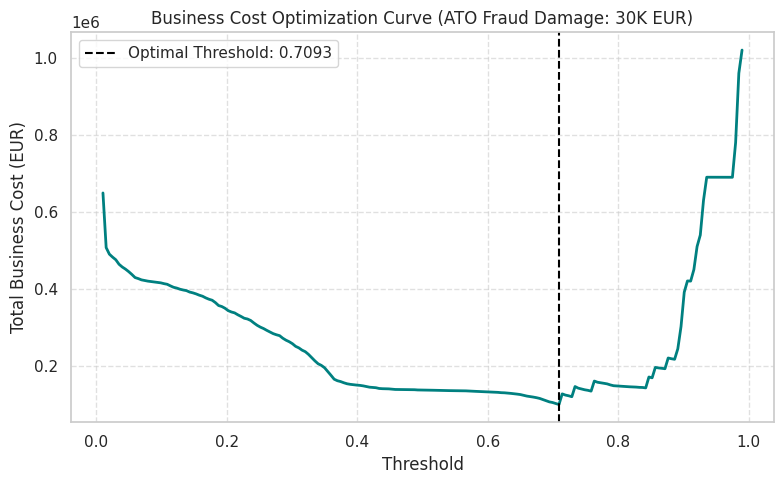

In [50]:
# ====================================================
# Cost-Sensitive Threshold Optimization & Curve (EUR Scenario)
# ====================================================

# 1. Predict fraud probabilities on the chronological test set
probs_test = final_cat_model.predict_proba(X_test)[:, 1]

# 2. Define financial business costs (EUR)
cost_fn = 30000  # Cost per False Negative (missed ATO attack)
cost_fp = 30     # Cost per False Positive (user friction / verification overhead)
cost_tp = 3      # Cost per True Positive (alert handling / response cost)

thresholds_list = np.linspace(0.01, 0.99, 200)
total_costs = []

# 3. Compute total expected business cost across candidate thresholds
for th in thresholds_list:
    y_pred_th = (probs_test >= th).astype(int)
    fp = np.sum((y_pred_th == 1) & (y_test == 0))
    fn = np.sum((y_pred_th == 0) & (y_test == 1))
    tp = np.sum((y_pred_th == 1) & (y_test == 1))

    cost = (fn * cost_fn) + (fp * cost_fp) + (tp * cost_tp)
    total_costs.append(cost)

# 4. Identify the optimal threshold that minimizes total business cost
optimal_th = thresholds_list[np.argmin(total_costs)]
min_cost = np.min(total_costs)

y_pred_opt = (probs_test >= optimal_th).astype(int)
fp_opt = int(np.sum((y_pred_opt == 1) & (y_test == 0)))
fn_opt = int(np.sum((y_pred_opt == 0) & (y_test == 1)))
tp_opt = int(np.sum((y_pred_opt == 1) & (y_test == 1)))

loss_fn_opt = fn_opt * cost_fn
loss_fp_opt = fp_opt * cost_fp
loss_tp_opt = tp_opt * cost_tp

print(f"Optimal Threshold for Cost Minimization (Sweet Spot): {optimal_th:.4f}")
print(f"Minimum Total Business Cost: {min_cost:,.0f} EUR")
print("--- Cost Breakdown (Uchiwake) ---")
print(f"  False Negatives (FN = {fn_opt:,}): {loss_fn_opt:>10,} EUR")
print(f"  False Positives (FP = {fp_opt:,}): {loss_fp_opt:>10,} EUR")
print(f"  True Positives  (TP = {tp_opt:,}): {loss_tp_opt:>10,} EUR")

# 5. Plot the business cost optimization curve
plt.figure(figsize=(8, 5))
plt.plot(thresholds_list, total_costs, color='teal', linewidth=2)
plt.axvline(optimal_th, color='black', linestyle='--', label=f'Optimal Threshold: {optimal_th:.4f}')
plt.title('Business Cost Optimization Curve (ATO Fraud Damage: 30K EUR)')
plt.xlabel('Threshold')
plt.ylabel('Total Business Cost (EUR)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### 11.4 Final Predictions & Evaluation (Threshold = 0.7093)

We apply the cost-optimal probability threshold (**0.7093**) to `final_cat_model` predictions on the test set and inspect the resulting classification report and confusion matrix.

In [51]:
# ==========================================
# Final Predictions & Evaluation at Optimal Threshold (0.7093)
# ==========================================

# 1. Obtain predicted probabilities from the model
y_pred_proba = final_cat_model.predict_proba(X_test)[:, 1]

# 2. Apply the optimal threshold (0.7093) to convert probabilities into binary predictions (0 or 1)
optimal_threshold = 0.7093
y_pred_custom = (y_pred_proba >= optimal_threshold).astype(int)

# 3. Print the final classification report and confusion matrix
from sklearn.metrics import classification_report, confusion_matrix

print("--- Final Classification Results ---")
print(classification_report(y_test, y_pred_custom))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_custom))

--- Final Classification Results ---
              precision    recall  f1-score   support

           0       1.00      0.94      0.97     39984
           1       0.02      0.98      0.04        45

    accuracy                           0.94     40029
   macro avg       0.51      0.96      0.50     40029
weighted avg       1.00      0.94      0.97     40029

Confusion Matrix:
 [[37614  2370]
 [    1    44]]


### 11.5 Evaluation Results & Business Trade-Off Analysis
Applying the cost-optimal probability threshold (**0.7093**) on the chronological test set (**40,029** login events, including **45** confirmed attacks and **39,984** legitimate logins) yields the following operational and financial outcomes:
- **High Attack Capture (44 / 45 Detected, Recall ~0.98):** Out of **45** ATO attacks, **44** are caught and only **1** goes undetected, keeping missed-attack losses to **€30,000** (`1 × €30,000`).
- **Controlled Friction vs. Severe Risk (2,370 False Alarms):** Out of **39,984** legitimate logins, **37,614** pass cleanly and **2,370** trigger false alarms (**€71,100** in verification/friction cost, `2,370 × €30`), alongside **44** handled true-positive alerts (**€132** in response cost, `44 × €3`). Precision is **0.02** (overall accuracy **0.94**) because the threshold deliberately prioritizes preventing high-impact account takeovers over minimizing low-unit verification friction.
- **Minimum Total Business Loss (101,232 EUR):** Combining all three cost components (`€30,000 + €71,100 + €132`) brings total expected loss down to **101,232 EUR**, representing the lowest-cost operating point across all evaluated thresholds.
- **Strategic & Regulatory Context:** In an EU operational environment, accepting manageable verification friction to minimize severe account takeovers is a deliberate risk-management choice. A missed login leading to a data breach or compromise can trigger **GDPR fines** (up to 4% of global annual turnover or €20 million, whichever is higher), **forensic and incident response costs** (typically €50,000–€500,000 for external investigation and system recovery), as well as customer churn and brand damage. Consequently, the €30,000 per-miss cost acts as a conservative lower bound relative to severe downside risk, making the €71,100 friction cost a rational "insurance" investment to protect the business against catastrophic outcomes.

## 12 - SHAP (Model Interpretability & Feature Attribution)
The purpose of this section is to apply **SHAP** (SHapley Additive exPlanations) to the final **CatBoost** model (`final_cat_model`) to quantitatively visualize and verify how individual features contribute to predicted Account Takeover (ATO) probabilities (at the **0.7093** operating threshold).

* **Ensuring Detection Transparency:** Evaluates whether contextual signals (such as country/region and device attributes), login timing and behavioral patterns, and anomaly/outlier scores behave consistently with security domain knowledge.
* **Supporting Governance & Accountability:** Moves beyond a black-box model by making predictions interpretable at the individual alert level—for both high-risk detections (TP) and false alarms (FP)—supporting regulatory alignment in the EU (explainability under GDPR) and operational efficiency (faster alert triage for SOC analysts).

--- Top 15 Features (Mean Absolute SHAP Value) ---


,feature,mean_abs_shap
0,IP Address,1.121213
1,user_unique_ips,1.078555
2,Device Type,0.955898
3,Login Successful,0.847889
4,Country,0.745358
5,login_count_per_user,0.699475
6,ip_rarity_ratio,0.385763
7,time_diff_previous_login,0.235844
8,Month,0.184505
9,login_dayofweek,0.096815


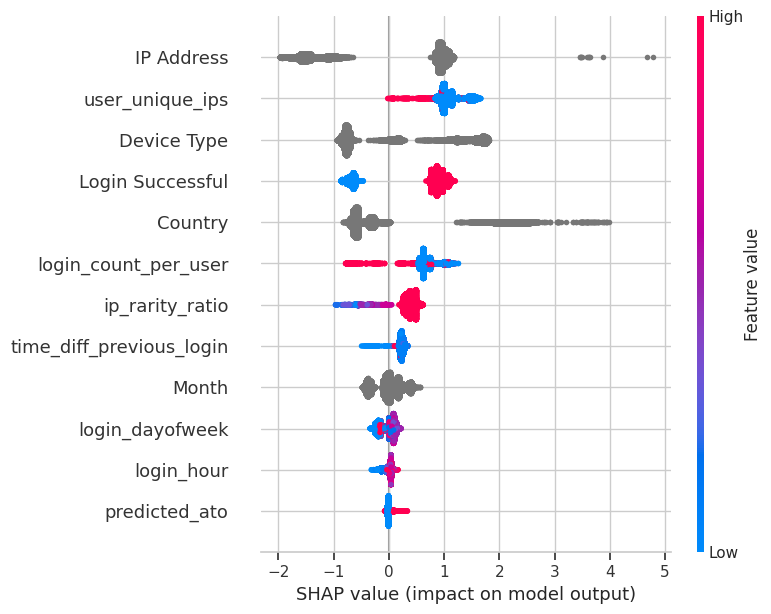

In [52]:
import shap

# ---------------------------------------------------------
# 1. Automatic Extraction & String Conversion of Categorical Columns
# ---------------------------------------------------------
cat_cols = X_test.select_dtypes(include=["object", "category"]).columns.tolist()

X_shap = X_test.copy()
if len(cat_cols) > 0:
  for col in cat_cols:
    X_shap[col] = X_shap[col].astype(str)

# ---------------------------------------------------------
# 2. CatBoost Native SHAP Calculation
# ---------------------------------------------------------
# Use TreeExplainer for fast SHAP value computation
explainer = shap.TreeExplainer(final_cat_model)
shap_values_raw = explainer.shap_values(X_shap)

# Extract Class 1 (ATO attack) SHAP values if returned as a list; otherwise use directly
if isinstance(shap_values_raw, list):
  shap_vals = shap_values_raw[1]  # SHAP values ​​for Class 1 (ATO attacks)
else:
  shap_vals = shap_values_raw

# ---------------------------------------------------------
# 3. Top 15 Feature Ranking by Mean Absolute SHAP Value
# ---------------------------------------------------------
mean_abs_shap = (
    pd.DataFrame({
        "feature": X_shap.columns,
        "mean_abs_shap": np.abs(shap_vals).mean(axis=0),
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

print("--- Top 15 Features (Mean Absolute SHAP Value) ---")
display(mean_abs_shap.head(15))

# ---------------------------------------------------------
# 4. Summary Plot (Beeswarm Plot)
# ---------------------------------------------------------
shap.summary_plot(shap_vals, X_shap, max_display=15)

### 12.1 SHAP Feature Attribution & Interpretation

Evaluating SHAP values on the final model (`final_cat_model`)—via the mean absolute SHAP ranking and summary plot—clarifies which signals drive Account Takeover (ATO) predictions.

- **Strong Impact from Network, User-IP Diversity, and Context:** `IP Address` (mean absolute SHAP: `1.121213`), `user_unique_ips` (`1.078555`), `Device Type` (`0.955898`), and `Country` (`0.745358`) rank at the top, showing that connection origin, device context, country, and per-user IP diversity play primary roles. The summary plot also highlights pronounced positive SHAP excursions for specific `IP Address` and `Country` values.
- **Authentication Outcome, Activity Volume, and Anomaly Indicators:** `Login Successful` (`0.847889`) and `login_count_per_user` (`0.699475`), alongside `ip_rarity_ratio` (`0.385763`) and `time_diff_previous_login` (`0.235844`), help capture deviations from regular login behavior.
- **Temporal & Unsupervised-Derived Signals:** `Month` (`0.184505`), `login_dayofweek` (`0.096815`), `login_hour` (`0.046487`), and `predicted_ato` (`0.023572`) provide complementary context across calendar/time patterns and anomaly indicators.



---



## 13 - Conclusion

This section  summarize the rationale behind the progressive evolution of our Account Takeover (ATO) detection pipeline—from **Isolation Forest (unsupervised)** to **LightGBM (supervised)**, and finally to **CatBoost with business cost optimization and SHAP explainability**—and to validate our decision-making framework based on SHAP feature attributions.

---

### Model Evolution & Rationale

1. **Stage 1: Baseline with Isolation Forest (Unsupervised Anomaly Detection)**
   - **Rationale:** Because confirmed attack labels are extremely rare (around 0.07% of login events), Isolation Forest was introduced first as a "zero-day baseline" to detect statistical outliers without relying on labels.
   - **Limitation Encountered:** The boundary between statistical anomalies and actual malicious ATO attempts remained ambiguous, and it could not directly learn from available attack labels.

2. **Stage 2: Transition to LightGBM (Supervised Learning)**
   - **Rationale:** Because labeled data was available, we moved to LightGBM—a standard supervised gradient boosting framework—to achieve stronger attack discrimination.
   - **Key Validation:** We tested class-imbalance handling techniques (such as sampling and class-weight adjustments) and used it as a supervised benchmark to evaluate detection behavior.

3. **Stage 3: Final Solution with CatBoost, EUR Cost Optimization & SHAP Explainability**
   - **Rationale & SHAP Validation:** We selected **CatBoost** as our final model because it processes high-cardinality categorical features (such as `IP Address`, `Device Type`, and `Country`) natively without one-hot encoding and offers strong resistance to overfitting. SHAP attribution on `final_cat_model` confirmed that network, context, and authentication outcome signals dominate prediction strength—led by `IP Address` (mean absolute SHAP: `1.121213`), `user_unique_ips` (`1.078555`), `Device Type` (`0.955898`), `Login Successful` (`0.847889`), `Country` (`0.745358`), and `login_count_per_user` (`0.699475`). Additionally, `ip_rarity_ratio` (`0.385763`), `time_diff_previous_login` (`0.235844`), temporal attributes (`Month`, `login_dayofweek`, `login_hour`), and unsupervised score (`predicted_ato`) provide essential secondary context, proving the real-world domain validity of our detection signals.
   - **Business Integration:** Rather than optimizing purely for standard ML metrics (such as F1-score or accuracy), we formulated asymmetric financial costs: **€30,000** per missed attack, **€30** per false alarm (verification friction), and **€3** per handled true-positive alert. Applying the cost-minimizing threshold (**0.7093**) achieves a minimum total expected loss of **€101,232**, catching **44 out of 45** attacks (only **1** missed attack = **€30,000**) while mitigating severe downside risks in an EU environment such as GDPR regulatory exposure and forensic incident response costs.

---

### Conclusion

By progressing from unsupervised exploration to supervised modeling, combining network, contextual, behavioral/temporal, and anomaly signals with high-cardinality features, validating feature contributions on the final CatBoost model with SHAP, and aligning threshold selection with EUR cost optimization, this project goes beyond a simple model comparison. It presents a business-driven, highly explainable security ML pipeline tailored to real-world operational and financial risks.